In [2]:
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_google_genai import GoogleGenerativeAIEmbeddings, ChatGoogleGenerativeAI
from langchain_core.tools import tool
from langchain_classic.agents import AgentExecutor, create_tool_calling_agent
from langchain_core.prompts import ChatPromptTemplate

from dotenv import load_dotenv

import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point, MultiPolygon

import time
import os
import sys
import contextlib
import io
from IPython.display import Image, Markdown, display
import unicodedata
from typing import Optional

# API KEY
load_dotenv()
api_key = os.getenv("GEMINI_API_KEY")

if api_key:
  print("API key cargada correctamente")
else:
  print("No se encontró GEMINI_API_KEY en el archivo .env")

# Enbeddings
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

os.makedirs("./generated_images", exist_ok=True)

API key cargada correctamente


## Cargar base vectorial local

In [3]:
# Cargar la base vectorial Chroma ya existente
vectorstore = Chroma(
    collection_name="smn_documentos",
    embedding_function=embeddings,
    persist_directory="./chroma_db_smn"
)

print(
    "Documentos cargados desde Chroma:",
    vectorstore._collection.count()
)

# Crear retriever
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 5}
)

Documentos cargados desde Chroma: 367


## Cargar PDFs y generar base vectorial Chroma

**NOTA:** *Se detectan documentos existentes ya cargados. Solo se tienen en cuenta documentos nuevos.*

In [31]:
# Lista de documentos existentes
registros_existentes = vectorstore._collection.get(include=["metadatas"])
fuentes_procesadas = set()

if registros_existentes and registros_existentes.get("metadatas"):
    for meta in registros_existentes["metadatas"]:
        if meta and "source" in meta:
            fuentes_procesadas.add(os.path.abspath(meta["source"]))

# Cargar PDFs
loader = PyPDFDirectoryLoader("files")
todos_los_documentos = loader.load()

# Documentos nuevos
documentos_nuevos = [
    doc for doc in todos_los_documentos 
    if os.path.abspath(doc.metadata.get("source", "")) not in fuentes_procesadas
]

print(f"Páginas detectadas nuevas: {len(documentos_nuevos)}")

if len(documentos_nuevos) == 0:
    print("No hay documentos nuevos para agregar.")
else:

    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=500,
        chunk_overlap=50
    )
    docs_split_nuevos = text_splitter.split_documents(documentos_nuevos)
    print(f"Nuevos fragmentos generados: {len(docs_split_nuevos)}")

    # Tener en cuenta los limites de la API
    batch_size = 75
    total = len(docs_split_nuevos)

    for i in range(0, total, batch_size):
        lote = docs_split_nuevos[i:i + batch_size]

        print(f"Procesando lote {i // batch_size + 1}: documentos {i + 1} a {min(i + batch_size, total)}")

        # add_documents agrega sin borrar el contenido anterior
        vectorstore.add_documents(lote)

        print(f"Documentos guardados hasta ahora: {vectorstore._collection.count()}")

        if i + batch_size < total:
            print("Esperando 60 segundos para respetar la cuota...\n")
            time.sleep(60)

    print("\nNuevos documentos agregados correctamente.")
    print("Total actualizado de documentos almacenados:", vectorstore._collection.count())

Páginas detectadas nuevas: 23
Nuevos fragmentos generados: 50
Procesando lote 1: documentos 1 a 50
Documentos guardados hasta ahora: 367

Nuevos documentos agregados correctamente.
Total actualizado de documentos almacenados: 367


## Funciones de ayuda

In [11]:
def normalizar_texto(texto: str) -> str:
  """Elimina tildes, mayúsculas y espacios innecesarios para facilitar coincidencias."""
  if not texto:
    return ""
  texto = texto.strip().upper()
  texto = unicodedata.normalize('NFD', texto)
  texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')
  return texto

def filtrar_poligono_tdf(geometry, modo: str = "continental"):
  """
  Separa los polígonos de la provincia de Tierra del Fuego, Antártida e Islas del Atlántico Sur.
  - 'continental': Conserva únicamente la Isla Grande e Isla de los Estados (lat > -55 y long < -55).
  - 'antartida': Conserva el Sector Antártico e islas australes (lat <= -55 o long >= -55).
  """
  if isinstance(geometry, MultiPolygon):
    if modo == "continental":
      polygons = [p for p in geometry.geoms if p.centroid.y > -55 and p.centroid.x < -55]
    elif modo == "antartida":
      polygons = [p for p in geometry.geoms if p.centroid.y <= -55 or p.centroid.x >= -55]
    else:
      return geometry
    return MultiPolygon(polygons) if polygons else geometry
  return geometry

## Carga de datasets

In [12]:
# ================================================================
# Temperaturas de los ultimos 365 dias
# ================================================================

print('='*50)
print("Temperaturas de los ultimos 365 dias")
print('='*50)

df_temps_365d = pd.read_csv(
    "datasets/temperaturas_365d.csv",
    parse_dates=["fecha"]
)

# Limpieza mínima de seguridad
df_temps_365d["estacion"] = df_temps_365d["estacion"].str.strip()

df_temps_365d = df_temps_365d.sort_values(
    by=["estacion", "fecha"]
).reset_index(drop=True)

# Verificaciones
print("\nCantidad de registros:", len(df_temps_365d))

print("\nRango de fechas:")
print("Desde:", df_temps_365d["fecha"].min())
print("Hasta:", df_temps_365d["fecha"].max())

print("\nValores faltantes:")
print(df_temps_365d.isna().sum())

display(df_temps_365d.head())

# ================================================================
# Estadísticas normales climatológicas 1991-2020
# ================================================================

print('='*50)
print("Estadísticas normales climatológicas 1991-2020")
print('='*50)

df_temps_normales = pd.read_csv(
    "datasets/estadisticas_normales_1991-2020.csv"
)

# Limpiar espacios por seguridad
df_temps_normales["estacion"] = df_temps_normales["estacion"].str.strip()
df_temps_normales["valor"] = df_temps_normales["valor"].str.strip()

print("\nCantidad de registros:", len(df_temps_normales))
print("Cantidad de estaciones:", df_temps_normales["estacion"].nunique())

display(df_temps_normales.head())

# ================================================================
# Lista de estaciones meteorologicas
# ================================================================

print('='*50)
print("Lista de estaciones meteorologicas")
print('='*50)

df_lista_estaciones = pd.read_csv(
    "datasets/estaciones_meteorologicas.csv"
)

REEMPLAZOS_PROVINCIAS = {
    "SANTIAGO DEL ES": "SANTIAGO DEL ESTERO",
    "TIERRA DEL FUEG": "TIERRA DEL FUEGO",
}

df_lista_estaciones["provincia"] = df_lista_estaciones["provincia"].str.strip().replace(REEMPLAZOS_PROVINCIAS)
df_lista_estaciones["PROVINCIA_NORM"] = df_lista_estaciones["provincia"].astype(str).apply(normalizar_texto)

print("\nCantidad de registros:", len(df_lista_estaciones))

display(df_lista_estaciones.head())

# ================================================================
# Mapa base de provincias
# ================================================================

print('='*50)
print("Mapa base de provincias")
print('='*50)

path_geojson = "./data/provincias.geojson"

if os.path.exists(path_geojson):
    gdf_provincias = gpd.read_file(path_geojson)
    gdf_provincias["NOMBRE_NORM"] = gdf_provincias["nombre"].astype(str).apply(normalizar_texto)
    print("Cantidad de provincias/entidades:", len(gdf_provincias))
    display(gdf_provincias.head())
else:
    print(f"\n[ERROR] No se encontró el archivo del mapa provincial en {path_geojson}")
    gdf_provincias = None


Temperaturas de los ultimos 365 dias

Cantidad de registros: 42949

Rango de fechas:
Desde: 2025-08-27 00:00:00
Hasta: 2026-08-26 00:00:00

Valores faltantes:
fecha          0
tmax        2019
tmin         552
estacion       0
dtype: int64


,fecha,tmax,tmin,estacion
0,2025-08-27,20.0,12.0,AEROPARQUE AERO
1,2025-08-28,18.4,12.5,AEROPARQUE AERO
2,2025-08-29,20.3,14.3,AEROPARQUE AERO
3,2025-08-30,21.1,14.9,AEROPARQUE AERO
4,2025-08-31,18.1,15.1,AEROPARQUE AERO


Estadísticas normales climatológicas 1991-2020

Cantidad de registros: 784
Cantidad de estaciones: 98


,estacion,valor,enero,febrero,marzo,abril,mayo,junio,julio,agosto,septiembre,octubre,noviembre,diciembre
0,LA QUIACA OBSERVATORIO,Temperatura (°C),13.2,13.0,12.8,11.3,7.3,4.8,4.5,7.0,10.0,12.4,13.4,13.9
1,LA QUIACA OBSERVATORIO,Temperatura máxima (°C),20.6,20.4,20.6,20.3,17.8,16.3,16.1,18.0,20.0,21.7,22.5,22.2
2,LA QUIACA OBSERVATORIO,Temperatura mínima (°C),7.7,7.6,6.6,3.1,-2.5,-5.7,-6.2,-4.0,-0.4,3.3,5.5,7.3
3,LA QUIACA OBSERVATORIO,Humedad relativa (%),62.6,63.2,60.3,46.0,32.6,27.4,25.7,26.7,32.1,42.4,48.6,55.8
4,LA QUIACA OBSERVATORIO,Velocidad del Viento (km/h),6.5,6.8,6.7,5.5,4.8,5.5,5.9,6.7,7.9,7.9,7.7,7.1


Lista de estaciones meteorologicas

Cantidad de registros: 118


,nombre,provincia,latitud,longitud,altura,nro,nro_oaci,PROVINCIA_NORM
0,BASE BELGRANO II,ANTARTIDA,-77.866667,-34.616667,256,89034.0,SAYB,ANTARTIDA
1,BASE CARLINI (EX JUBANY),ANTARTIDA,-62.233333,-58.650000,11,89053.0,SAYJ,ANTARTIDA
2,BASE ESPERANZA,ANTARTIDA,-63.383333,-56.983333,24,88963.0,SAYE,ANTARTIDA
3,BASE MARAMBIO,ANTARTIDA,-64.233333,-56.616667,198,89055.0,SAWB,ANTARTIDA
4,BASE ORCADAS,ANTARTIDA,-60.733333,-44.733333,12,88968.0,SAYO,ANTARTIDA


Mapa base de provincias
Cantidad de provincias/entidades: 24


,id,nombre,nombre_completo,fuente,categoria,centroide,iso_id,iso_nombre,geometry,NOMBRE_NORM
0,02,Ciudad Autónoma de Buenos Aires,Ciudad Autónoma de Buenos Aires,IGN,Ciudad Autónoma,"{'lon': -58.445876325, 'lat': -34.614442065}",AR-C,Ciudad Autónoma de Buenos Aires,"POLYGON ((-58.45535 -34.52776, -58.45085 -34.5...",CIUDAD AUTONOMA DE BUENOS AIRES
1,58,Neuquén,Provincia del Neuquén,IGN,Provincia,"{'lon': -70.119897224, 'lat': -38.641982863}",AR-Q,Neuquén,"POLYGON ((-70.39341 -36.15624, -70.39499 -36.1...",NEUQUEN
2,74,San Luis,Provincia de San Luis,IGN,Provincia,"{'lon': -66.025231271, 'lat': -33.761103538}",AR-D,San Luis,"POLYGON ((-67.05547 -31.85605, -67.00593 -31.8...",SAN LUIS
3,82,Santa Fe,Provincia de Santa Fe,IGN,Provincia,"{'lon': -60.950687277, 'lat': -30.708822709}",AR-S,Santa Fe,"POLYGON ((-61.04639 -27.998, -58.884 -28, -58....",SANTA FE
4,46,La Rioja,Provincia de La Rioja,IGN,Provincia,"{'lon': -67.181757581, 'lat': -29.684937278}",AR-F,La Rioja,"POLYGON ((-68.52136 -27.81792, -68.51099 -27.8...",LA RIOJA


## Definicion de Tools

In [9]:
# Crear herramienta para buscar información en los PDF
@tool
def buscar_informacion_texto(query: str) -> str:
  """Útil para buscar explicaciones conceptuales, definiciones técnicas o informes climáticos en los documentos PDF."""
  results = retriever.invoke(query)
  
  if not results:
    return "No se encontró información relevante en los informes."

  # Formatear la respuesta incluyendo fuente y página
  respuesta = []
  for doc in results:
    fuente = doc.metadata.get("source", "PDF desconocido")
    pagina = doc.metadata.get("page", 0) + 1
    respuesta.append(f"--- [Fuente: {fuente} (Pág. {pagina})] ---\n{doc.page_content}")
  
  return "\n\n".join(respuesta)

In [8]:
# Crear herramienta para graficar temperaturas de una estación

@tool
def graficar_temperatura_estacion(
    estacion: str,
    fecha_inicio: str,
    fecha_fin: str
) -> str:
    """
    Genera un gráfico de temperatura máxima y mínima para una estación
    meteorológica del SMN dentro de un rango de fechas.

    Args:
        estacion: Nombre de la estación, por ejemplo "ROSARIO AERO".
        fecha_inicio: Fecha inicial en formato YYYY-MM-DD.
        fecha_fin: Fecha final en formato YYYY-MM-DD.
    """

    # Convertir las fechas recibidas a datetime
    inicio = pd.to_datetime(fecha_inicio, errors="coerce")
    fin = pd.to_datetime(fecha_fin, errors="coerce")

    if pd.isna(inicio) or pd.isna(fin):
        return "Las fechas deben tener formato YYYY-MM-DD."

    if inicio > fin:
        return "La fecha de inicio no puede ser posterior a la fecha de fin."

    # Buscar la estación ignorando mayúsculas/minúsculas
    nombre_buscado = estacion.strip().upper()

    estaciones = df_temps_365d["estacion"].dropna().unique()

    coincidencias = [
        e for e in estaciones
        if nombre_buscado in e.upper()
    ]

    if len(coincidencias) == 0:
        return f"No se encontró ninguna estación que coincida con '{estacion}'."

    # Si encuentra varias estaciones, pedir una más específica
    if len(coincidencias) > 1:
        opciones = ", ".join(coincidencias[:10])
        return (
            f"Se encontraron varias estaciones para '{estacion}': "
            f"{opciones}. Indicá una estación más específica."
        )

    estacion_encontrada = coincidencias[0]

    # Filtrar estación y rango de fechas
    datos = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_encontrada) &
        (df_temps_365d["fecha"] >= inicio) &
        (df_temps_365d["fecha"] <= fin)
    ].copy()

    if datos.empty:
        return (
            f"No hay datos para {estacion_encontrada} "
            f"entre {fecha_inicio} y {fecha_fin}."
        )

    # Crear gráfico
    plt.figure(figsize=(12, 6))

    plt.plot(
        datos["fecha"],
        datos["tmax"],
        label="Temperatura máxima"
    )

    plt.plot(
        datos["fecha"],
        datos["tmin"],
        label="Temperatura mínima"
    )

    plt.xlabel("Fecha")
    plt.ylabel("Temperatura (°C)")
    plt.title(
        f"Temperaturas en {estacion_encontrada}\n"
        f"{fecha_inicio} a {fecha_fin}"
    )

    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()

    nombre_archivo = "./generated_images/grafico_temperatura.png"
    plt.savefig(nombre_archivo)
    plt.close()

    return (
        f"Gráfico generado correctamente para {estacion_encontrada}. "
        f"Se utilizaron {len(datos)} registros entre "
        f"{fecha_inicio} y {fecha_fin}.\n"
        f"IMAGEN_GENERADA:{nombre_archivo}"
    )

In [7]:
# Crear herramienta para comparar temperatura con normal climatológica
@tool
def comparar_temperatura_con_normal(
    estacion: str,
    mes: str,
    anio: int,
    tipo_temperatura: str
) -> str:
    """
    Compara la temperatura observada de una estación del SMN durante un mes
    con la normal climatológica 1991-2020.

    Args:
        estacion: Nombre de la estación, por ejemplo "ROSARIO AERO".
        mes: Mes en español, por ejemplo "julio".
        anio: Año a analizar, por ejemplo 2026.
        tipo_temperatura: Debe ser "maxima" o "minima".
    """

    # Normalizar parámetros recibidos
    estacion_buscada = estacion.strip().upper()
    mes = mes.strip().lower()
    tipo_temperatura = tipo_temperatura.strip().lower()

    meses = {
        "enero": 1,
        "febrero": 2,
        "marzo": 3,
        "abril": 4,
        "mayo": 5,
        "junio": 6,
        "julio": 7,
        "agosto": 8,
        "septiembre": 9,
        "octubre": 10,
        "noviembre": 11,
        "diciembre": 12
    }

    if mes not in meses:
        return f"Mes inválido: {mes}."

    # Definir qué columnas utilizar según máxima o mínima
    if tipo_temperatura in ["maxima", "máxima"]:
        columna_observada = "tmax"
        variable_normal = "Temperatura máxima (°C)"
        nombre_tipo = "máxima"

    elif tipo_temperatura in ["minima", "mínima"]:
        columna_observada = "tmin"
        variable_normal = "Temperatura mínima (°C)"
        nombre_tipo = "mínima"

    else:
        return "El tipo de temperatura debe ser 'maxima' o 'minima'."

    # Buscar coincidencias de estación en los datos diarios
    estaciones = df_temps_365d["estacion"].dropna().unique()

    coincidencias = [
        e for e in estaciones
        if estacion_buscada in e.upper()
    ]

    if len(coincidencias) == 0:
        return f"No se encontró la estación '{estacion}'."

    if len(coincidencias) > 1:
        opciones = ", ".join(coincidencias[:10])
        return (
            f"Se encontraron varias estaciones para '{estacion}': "
            f"{opciones}. Indicá una estación más específica."
        )

    estacion_encontrada = coincidencias[0]

    # Filtrar registros del mes y año solicitados
    numero_mes = meses[mes]

    datos_mes = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_encontrada) &
        (df_temps_365d["fecha"].dt.year == anio) &
        (df_temps_365d["fecha"].dt.month == numero_mes)
    ]

    if datos_mes.empty:
        return (
            f"No hay datos observados para {estacion_encontrada} "
            f"durante {mes} de {anio}."
        )

    # Calcular promedio observado
    promedio_observado = datos_mes[columna_observada].mean()

    if pd.isna(promedio_observado):
        return (
            f"No hay suficientes mediciones de temperatura {nombre_tipo} "
            f"para {estacion_encontrada} durante {mes} de {anio}."
        )

    # Buscar normal climatológica 1991-2020
    normal = df_temps_normales[
        (df_temps_normales["estacion"].str.upper() == estacion_encontrada.upper()) &
        (df_temps_normales["valor"] == variable_normal)
    ]

    if normal.empty:
        return (
            f"No se encontró la normal climatológica de temperatura "
            f"{nombre_tipo} para {estacion_encontrada}."
        )

    valor_normal = pd.to_numeric(
        normal.iloc[0][mes],
        errors="coerce"
    )

    if pd.isna(valor_normal):
        return (
            f"No existe un valor normal disponible para "
            f"{estacion_encontrada} en {mes}."
        )

    # Calcular diferencia
    diferencia = promedio_observado - valor_normal

    # Generar gráfico
    plt.figure(figsize=(7, 5))

    plt.bar(
        [f"{mes.capitalize()} {anio}", "Normal 1991-2020"],
        [promedio_observado, valor_normal]
    )

    plt.ylabel("Temperatura (°C)")
    plt.title(
        f"Temperatura {nombre_tipo} - {estacion_encontrada}\n"
        f"{mes.capitalize()} {anio} vs. normal climatológica"
    )

    plt.tight_layout()

    nombre_archivo = "./generated_images/comparacion_temperatura_normal.png"
    plt.savefig(nombre_archivo)
    plt.close()

    # Interpretación sencilla
    if diferencia > 0:
        comparacion = "por encima"
    elif diferencia < 0:
        comparacion = "por debajo"
    else:
        comparacion = "igual"

    return (
        f"En {estacion_encontrada}, la temperatura {nombre_tipo} promedio "
        f"observada durante {mes} de {anio} fue de "
        f"{promedio_observado:.1f} °C. "
        f"La normal climatológica 1991-2020 para ese mes es "
        f"{valor_normal:.1f} °C. "
        f"La diferencia fue de {diferencia:+.1f} °C, "
        f"por lo que estuvo {comparacion} de lo normal.\n"
        f"IMAGEN_GENERADA:{nombre_archivo}"
    )

In [6]:
# Crear herramienta para consultar estaciones meteorológicas
@tool
def consultar_estaciones(
    provincia: Optional[str] = None,
    nombre: Optional[str] = None
) -> str:
    """
    Consulta las estaciones meteorológicas disponibles del SMN.

    Puede:
    - listar estaciones de una provincia;
    - buscar una estación por nombre;
    - devolver ubicación, altura y códigos de una estación.

    Args:
        provincia: Provincia a consultar, por ejemplo "SANTA FE".
        nombre: Nombre o parte del nombre de una estación,
                por ejemplo "ROSARIO".
    """

    datos = df_lista_estaciones.copy()

    # Filtrar por provincia si fue indicada
    if provincia:
        provincia_buscada = provincia.strip().upper()

        datos = datos[
            datos["provincia"]
            .astype(str)
            .str.upper()
            .str.contains(provincia_buscada, na=False)
        ]

    # Filtrar por nombre si fue indicado
    if nombre:
        nombre_buscado = nombre.strip().upper()

        datos = datos[
            datos["nombre"]
            .astype(str)
            .str.upper()
            .str.contains(nombre_buscado, na=False)
        ]

    if datos.empty:
        return "No se encontraron estaciones que coincidan con la búsqueda."

    # Evitar respuestas gigantes
    if len(datos) > 20:
        datos = datos.head(20)
        aviso = (
            "\nSe encontraron más de 20 estaciones. "
            "Se muestran solamente las primeras 20."
        )
    else:
        aviso = ""

    resultados = []

    for _, fila in datos.iterrows():
        resultados.append(
            f"- {fila['nombre']} | "
            f"Provincia: {fila['provincia']} | "
            f"Latitud: {fila['latitud']} | "
            f"Longitud: {fila['longitud']} | "
            f"Altura: {fila['altura']} | "
            f"N° SMN: {fila['nro']} | "
            f"OACI: {fila['nro_oaci']}"
        )

    return (
        f"Se encontraron {len(datos)} estaciones:\n\n"
        + "\n".join(resultados)
        + aviso
    )

In [5]:
# Crear herramienta para comparar temperaturas de dos estaciones
@tool
def comparar_temperaturas_estaciones(
    estacion_1: str,
    estacion_2: str,
    fecha_inicio: str,
    fecha_fin: str,
    tipo_temperatura: str
) -> str:
    """
    Compara la temperatura promedio de dos estaciones meteorológicas
    del SMN dentro de un rango de fechas.

    Args:
        estacion_1: Primera estación, por ejemplo "ROSARIO".
        estacion_2: Segunda estación, por ejemplo "CORDOBA".
        fecha_inicio: Fecha inicial en formato YYYY-MM-DD.
        fecha_fin: Fecha final en formato YYYY-MM-DD.
        tipo_temperatura: Debe ser "maxima" o "minima".
    """

    inicio = pd.to_datetime(fecha_inicio, errors="coerce")
    fin = pd.to_datetime(fecha_fin, errors="coerce")

    if pd.isna(inicio) or pd.isna(fin):
        return "Las fechas deben tener formato YYYY-MM-DD."

    if inicio > fin:
        return "La fecha de inicio no puede ser posterior a la fecha de fin."

    tipo = tipo_temperatura.strip().lower()

    if tipo in ["maxima", "máxima"]:
        columna = "tmax"
        nombre_tipo = "máxima"
    elif tipo in ["minima", "mínima"]:
        columna = "tmin"
        nombre_tipo = "mínima"
    else:
        return "El tipo de temperatura debe ser 'maxima' o 'minima'."

    def buscar_estacion(nombre):
        nombre_buscado = nombre.strip().upper()

        estaciones = df_temps_365d["estacion"].dropna().unique()

        coincidencias = [
            e for e in estaciones
            if nombre_buscado in e.upper()
        ]

        if len(coincidencias) == 0:
            return None, f"No se encontró ninguna estación que coincida con '{nombre}'."

        if len(coincidencias) > 1:
            opciones = ", ".join(coincidencias[:10])
            return None, (
                f"Se encontraron varias estaciones para '{nombre}': "
                f"{opciones}. Indicá una estación más específica."
            )

        return coincidencias[0], None

    estacion_1_real, error = buscar_estacion(estacion_1)

    if error:
        return error

    estacion_2_real, error = buscar_estacion(estacion_2)

    if error:
        return error

    datos_1 = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_1_real) &
        (df_temps_365d["fecha"] >= inicio) &
        (df_temps_365d["fecha"] <= fin)
    ]

    datos_2 = df_temps_365d[
        (df_temps_365d["estacion"] == estacion_2_real) &
        (df_temps_365d["fecha"] >= inicio) &
        (df_temps_365d["fecha"] <= fin)
    ]

    if datos_1.empty:
        return f"No hay datos disponibles para {estacion_1_real} en ese período."

    if datos_2.empty:
        return f"No hay datos disponibles para {estacion_2_real} en ese período."

    promedio_1 = datos_1[columna].mean()
    promedio_2 = datos_2[columna].mean()

    if pd.isna(promedio_1) or pd.isna(promedio_2):
        return "No hay suficientes datos de temperatura para realizar la comparación."

    diferencia = promedio_1 - promedio_2

    # Crear gráfico
    plt.figure(figsize=(7, 5))

    plt.bar(
        [estacion_1_real, estacion_2_real],
        [promedio_1, promedio_2]
    )

    plt.ylabel("Temperatura (°C)")
    plt.title(
        f"Temperatura {nombre_tipo} promedio\n"
        f"{fecha_inicio} a {fecha_fin}"
    )

    plt.xticks(rotation=15)
    plt.tight_layout()

    nombre_archivo = "./generated_images/comparacion_estaciones.png"

    plt.savefig(nombre_archivo)
    plt.close()

    if diferencia > 0:
        conclusion = (
            f"{estacion_1_real} tuvo una temperatura {nombre_tipo} "
            f"promedio {abs(diferencia):.1f} °C mayor que {estacion_2_real}."
        )
    elif diferencia < 0:
        conclusion = (
            f"{estacion_2_real} tuvo una temperatura {nombre_tipo} "
            f"promedio {abs(diferencia):.1f} °C mayor que {estacion_1_real}."
        )
    else:
        conclusion = "Ambas estaciones tuvieron el mismo promedio."

    return (
        f"{estacion_1_real}: {promedio_1:.1f} °C.\n"
        f"{estacion_2_real}: {promedio_2:.1f} °C.\n"
        f"{conclusion}\n"
        f"IMAGEN_GENERADA:{nombre_archivo}"
    )

In [4]:
# Herramienta para graficar ubicacion de las estaciones, en todo el pais o por provincia

# NOTA: Existe un bug, si no se completa la provincia y se ingresa por ejemplo 'santa', termina devolviendo tanto santa fe como santa cruz. Algo parecido pasa si se ingresa 'ant' o similar
@tool
def generar_mapa_estaciones(provincia: Optional[str] = None) -> str:
    """
    Genera y guarda un mapa con las estaciones meteorológicas del SMN sobre el mapa de provincias argentinas.

    ¿Cuándo usar esta herramienta?:
    - Cuando el usuario pida ver, ubicar o graficar las estaciones meteorológicas en un mapa.
    - Cuando solicite ver las estaciones a nivel nacional o filtradas por una provincia/sector en particular.

    Args:
        provincia (str, opcional): Nombre de la provincia para filtrar el mapa.
            Ejemplos válidos: 'BUENOS AIRES', 'MENDOZA', 'CORDOBA', 'CAPITAL FEDERAL', 'TIERRA DEL FUEGO', 'ANTARTIDA', etc.
            Si es None o se omite, se generará el mapa nacional completo.

    Returns:
        str: Ruta de la imagen en formato 'IMAGEN_GENERADA:nombre_del_archivo.png' o mensaje de error.
    """
    # 1. Validar que las variables globales existan
    if 'gdf_provincias' not in globals() or gdf_provincias is None:
        return "Error: El mapa base 'gdf_provincias' no ha sido cargado en el entorno."
    if 'df_lista_estaciones' not in globals() or df_lista_estaciones is None:
        return "Error: El dataset 'df_lista_estaciones' no ha sido cargado en el entorno."

    # Se copia para evitar alterar las geometrías y datos globales
    gdf_prov = gdf_provincias.copy()
    df_estaciones = df_lista_estaciones.copy()

    # Garantizar que PROVINCIA_NORM exista
    if "PROVINCIA_NORM" not in df_estaciones.columns:
        df_estaciones["PROVINCIA_NORM"] = df_estaciones["provincia"].astype(str).apply(normalizar_texto)

    # 2. Determinar provincia o sector solicitado
    provincia_solicitada = None
    es_antartida = False
    patron_csv = None
    patron_geojson = None

    if provincia and provincia.strip():
        p_norm = normalizar_texto(provincia)

        # Mapeos explícitos para casos especiales
        if any(k in p_norm for k in ["CABA", "CAPITAL", "CIUDAD AUTONOMA"]):
            provincia_solicitada = "CAPITAL FEDERAL"
            patron_csv = "CAPITAL|CABA|CIUDAD AUTONOMA"
            patron_geojson = "CIUDAD AUTONOMA"
        elif any(k in p_norm for k in ["ANTARTIDA", "SECTOR ANTARTICO", "ANTARTIDA ARGENTINA"]):
            provincia_solicitada = "ANTARTIDA"
            es_antartida = True
            patron_csv = "ANTAR"
            patron_geojson = "TIERRA DEL FUEGO"
        elif any(k in p_norm for k in ["TIERRA DEL FUEG", "FUEGO", "TDF"]):
            provincia_solicitada = "TIERRA DEL FUEGO"
            patron_csv = "TIERRA DEL FUEGO"
            patron_geojson = "TIERRA DEL FUEGO"
        elif "BUENOS AIRES" in p_norm and "CIUDAD" not in p_norm and "CAPITAL" not in p_norm:
            provincia_solicitada = "BUENOS AIRES"
            patron_csv = "BUENOS AIRES"
            patron_geojson = "BUENOS AIRES"
        else:
            patron_csv = p_norm
            patron_geojson = p_norm

        # Filtrar estaciones en el DataFrame
        if provincia_solicitada == "BUENOS AIRES":
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False) & \
                    ~df_estaciones["PROVINCIA_NORM"].str.contains("CAPITAL|CABA|CIUDAD", na=False)
        elif provincia_solicitada == "TIERRA DEL FUEGO":
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False) & \
                    ~df_estaciones["PROVINCIA_NORM"].str.contains("ANTAR", na=False)
        else:
            m_csv = df_estaciones["PROVINCIA_NORM"].str.contains(patron_csv, na=False)

        df_filtrado = df_estaciones[m_csv]

        if df_filtrado.empty:
            provincias_disponibles = sorted(df_estaciones["provincia"].dropna().unique().tolist())
            return (
                f"No se encontraron estaciones para la provincia '{provincia}'. "
                f"Las opciones disponibles son: {', '.join(provincias_disponibles)}"
            )

        # Si no era un caso especial (CABA, Antártida, etc.), asignamos el nombre canonical oficial extraído del dataset
        if not provincia_solicitada:
            provincia_solicitada = df_filtrado["provincia"].iloc[0].upper()

        df_plot = df_filtrado
    else:
        df_plot = df_estaciones

    # 3. Ajustar la geometría de Tierra del Fuego / Antártida según el modo de visualización
    mask_tdf = gdf_prov["NOMBRE_NORM"].str.contains("TIERRA DEL FUEGO", na=False)
    
    if es_antartida:
        gdf_prov.loc[mask_tdf, "geometry"] = gdf_prov.loc[mask_tdf, "geometry"].apply(
            lambda g: filtrar_poligono_tdf(g, modo="antartida")
        )
    else:
        gdf_prov.loc[mask_tdf, "geometry"] = gdf_prov.loc[mask_tdf, "geometry"].apply(
            lambda g: filtrar_poligono_tdf(g, modo="continental")
        )

    # 4. Convertir DataFrame de estaciones a GeoDataFrame (Longitud X, Latitud Y)
    geometry_estaciones = [Point(xy) for xy in zip(df_plot["longitud"], df_plot["latitud"])]
    gdf_estaciones = gpd.GeoDataFrame(df_plot, geometry=geometry_estaciones, crs="EPSG:4326")

    # 5. Crear la figura y dibujar polígonos de provincias
    fig, ax = plt.subplots(figsize=(10, 14))

    gdf_prov.plot(
        ax=ax,
        facecolor="#e9ecef",
        edgecolor="#8c959f",
        linewidth=0.7
    )

    # 6. Resaltar la provincia/sector seleccionado
    gdf_prov_sel = None
    if provincia_solicitada:
        if provincia_solicitada == "BUENOS AIRES":
            m_geo = gdf_prov["NOMBRE_NORM"].str.contains(patron_geojson, na=False) & \
                    ~gdf_prov["NOMBRE_NORM"].str.contains("CIUDAD AUTONOMA", na=False)
        else:
            m_geo = gdf_prov["NOMBRE_NORM"].str.contains(patron_geojson, na=False)

        gdf_prov_sel = gdf_prov[m_geo]
        if not gdf_prov_sel.empty:
            gdf_prov_sel.plot(
                ax=ax,
                facecolor="#d0e1fd",
                edgecolor="#0d6efd",
                linewidth=2
            )

    # 7. Graficar los puntos de las estaciones
    gdf_estaciones.plot(
        ax=ax,
        marker="o",
        color="#d98302",
        markersize=100 if provincia_solicitada else 50,
        alpha=0.9,
        edgecolor="black",
        linewidth=1.5,
        label="Estaciones SMN",
        zorder=3
    )

    # 8. Definir encuadre y zoom (expandiendo el mapa en el eje sobrante)
    if provincia_solicitada and gdf_prov_sel is not None and not gdf_prov_sel.empty:
        if es_antartida:
            ax.set_xlim(-76, -23)
            ax.set_ylim(-90.5, -58)
            titulo = "Estaciones Meteorológicas SMN - Sector Antártico"
        else:
            p_minx, p_miny, p_maxx, p_maxy = gdf_prov_sel.total_bounds
            cx = (p_minx + p_maxx) / 2
            cy = (p_miny + p_maxy) / 2

            # Ancho y alto del bounding box con margen básico (15%)
            dx = max((p_maxx - p_minx) * 1.15, 0.4)
            dy = max((p_maxy - p_miny) * 1.15, 0.4)

            # Aspect ratio objetivo de la figura (14 alto / 10 ancho = 1.4)
            target_aspect = 14.0 / 10.0
            actual_aspect = dy / dx

            # Ajuste de límites: si el mapa es más ancho que la figura, expandimos alto; si es más alto, expandimos ancho
            if actual_aspect < target_aspect:
                dy = dx * target_aspect
            else:
                dx = dy / target_aspect

            # Asignar los límites centrados en la provincia
            
            if provincia_solicitada == 'TIERRA DEL FUEGO':
                ax.set_xlim((cx - dx / 2) - 4, (cx + dx / 2) + 4)
                ax.set_ylim(cy - dy / 2, cy + dy / 2)
            else:
                ax.set_xlim(cx - dx / 2, cx + dx / 2)
                ax.set_ylim(cy - dy / 2, cy + dy / 2)
            
            titulo = f"Estaciones Meteorológicas SMN - {provincia_solicitada}"
    else:
        # Encuadre para Argentina Continental
        minx, miny, maxx, maxy = gdf_prov.total_bounds
        ax.set_xlim(minx - 7, maxx + 7)
        ax.set_ylim(miny - 0.8, maxy + 0.8)
        titulo = "Red de Estaciones Meteorológicas SMN - República Argentina"

    # 9. Detalles estéticos
    plt.title(titulo, fontsize=16, fontweight="bold", pad=15)
    plt.xlabel("Longitud", fontsize=14)
    plt.ylabel("Latitud", fontsize=14)
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.legend(loc="upper right", fontsize=14)

    # 10. Guardar imagen
    nombre_archivo = "./generated_images/mapa_NACION.png" if not provincia_solicitada else f"./generated_images/mapa_{provincia_solicitada.replace(' ', '_')}.png"

    plt.tight_layout()
    fig.savefig(nombre_archivo, dpi=150)
    plt.close(fig)

    return f"IMAGEN_GENERADA:{nombre_archivo}"

In [181]:
resultado = generar_mapa_estaciones.invoke({
  # "provincia": 'antartida'
})

print(resultado)

IMAGEN_GENERADA:./generated_images/mapa_NACION.png


### Tests y ejemplos de uso

In [9]:
## PRUEBA DE BUSQUEDA DE INFORMACION

resultado_rag = buscar_informacion_texto.invoke({
    "query": "¿Cómo fueron las precipitaciones durante mayo de 2026?"
})

print(resultado_rag)

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 5)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
2
SMN
CARACTERÍSTICAS CLIMÁTICAS 
1 - PRECIPITACIÓN
1.1 - Precipitación media
Durante el mes de mayo, una extensa zona del país que comprende al Noroeste Argentino (NOA), 
Cuyo, centro y zona central de la Patagonia presentó precipitaciones inferiores a 20 mm (Figura 1- 
isolínea negra). En varias localidades no se registraron precipitaciones, por ejemplo: La Quiaca, Ceres,

--- [Fuente: files\Clim-Otoño 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Otoño  2026  - Vol. XXXVIII
6
SMN
FIG. 3 – Desvío de la precipitación con respecto a la normal 
1991-2020 (mm) de marzo, abril y mayo de 2026.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 9)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
6
SMN
FIG. 5 – Frecuencia de días con lluvia.
FIG. 6 – Frecuencia de días con lluvia de primera, 
segunda y tercera década.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 8)] ---
del territorio 

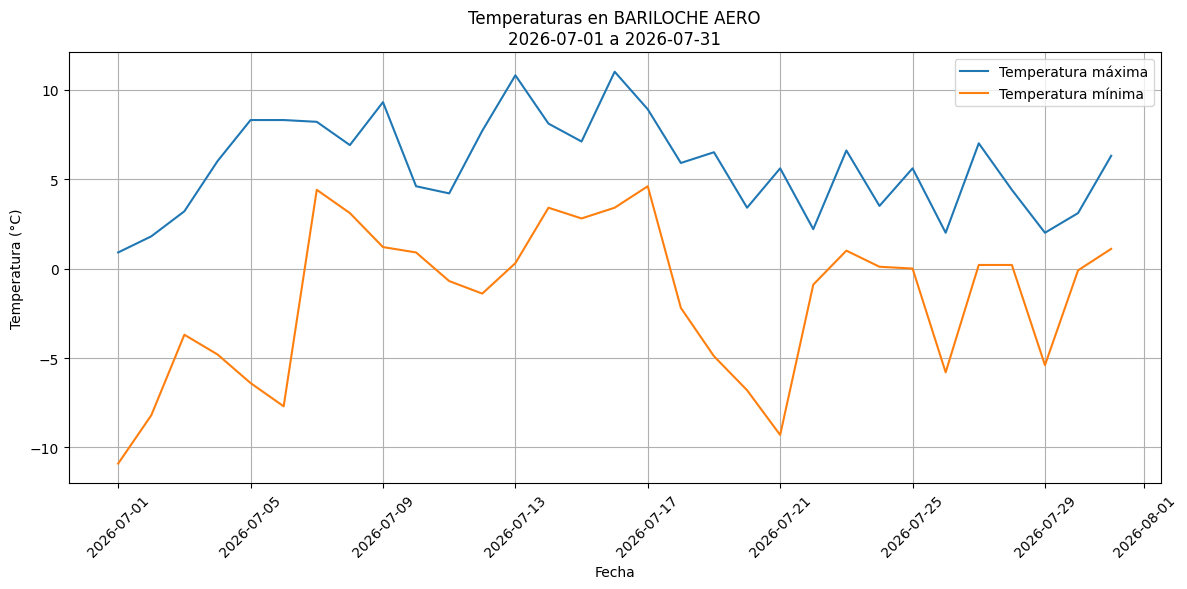

Gráfico generado correctamente para BARILOCHE AERO. Se utilizaron 31 registros entre 2026-07-01 y 2026-07-31.


In [8]:
# PRUEBA DE LA HERRAMIENTA DE GRAFICAR TEMPERATURA

resultado = graficar_temperatura_estacion.invoke({
    "estacion": "BARILOCHE AERO",
    "fecha_inicio": "2026-07-01",
    "fecha_fin": "2026-07-31"
})

print(resultado)

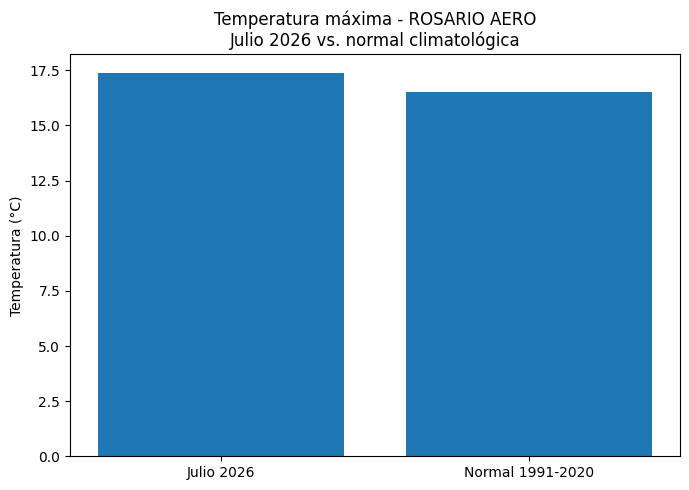

En ROSARIO AERO, la temperatura máxima promedio observada durante julio de 2026 fue de 17.4 °C. La normal climatológica 1991-2020 para ese mes es 16.5 °C. La diferencia fue de +0.9 °C, por lo que estuvo por encima de lo normal.


In [ ]:
# PRUEBA DE LA HERRAMIENTA DE COMPARACIÓN DE TEMPERATURA CON NORMAL CLIMATOLÓGICA

resultado_comparacion = comparar_temperatura_con_normal.invoke({
    "estacion": "ROSARIO AERO",
    "mes": "julio",
    "anio": 2026,
    "tipo_temperatura": "maxima"
})

print(resultado_comparacion)

In [19]:
# PRUEBA DE LA HERRAMIENTA DE CONSULTA DE ESTACIONES METEOROLÓGICAS
resultado_estaciones = consultar_estaciones.invoke({
    "provincia": "SANTA FE",
    "nombre": None
})

print(resultado_estaciones)

Se encontraron 7 estaciones:

- CERES AERO | Provincia: SANTA FE | Latitud: -29.866666666666667 | Longitud: -61.93333333333333 | Altura: 88 | N° SMN: 87257.0 | OACI: SANW
- RAFAELA AERO | Provincia: SANTA FE | Latitud: -31.266666666666666 | Longitud: -61.5 | Altura: 99 | N° SMN: 87360.0 | OACI: SAFR
- RECONQUISTA AERO | Provincia: SANTA FE | Latitud: -29.2 | Longitud: -59.68333333333333 | Altura: 53 | N° SMN: 87270.0 | OACI: SATR
- ROSARIO AERO | Provincia: SANTA FE | Latitud: -32.9 | Longitud: -60.766666666666666 | Altura: 25 | N° SMN: 87480.0 | OACI: SAAR
- SAUCE VIEJO AERO | Provincia: SANTA FE | Latitud: -31.7 | Longitud: -60.8 | Altura: 18 | N° SMN: 87371.0 | OACI: SAAV
- SUNCHALES AERO | Provincia: SANTA FE | Latitud: -30.95 | Longitud: -61.516666666666666 | Altura: 92 | N° SMN: 87356.0 | OACI: SAFS
- VENADO TUERTO AERO | Provincia: SANTA FE | Latitud: -33.666666666666664 | Longitud: -61.95 | Altura: 112 | N° SMN: 87468.0 | OACI: SAFV


In [ ]:
# PRUEBA DE LA HERRAMIENTA DE CONSULTA DE ESTACIONES METEOROLÓGICAS
resultado_estaciones = consultar_estaciones.invoke({
    "provincia": None,
    "nombre": "ROSARIO"
})

print(resultado_estaciones)

Se encontraron 1 estaciones:

- ROSARIO AERO | Provincia: SANTA FE | Latitud: -32.9 | Longitud: -60.766666666666666 | Altura: 25 | N° SMN: 87480.0 | OACI: SAAR


In [ ]:
# PRUEBA DE LA HERRAMIENTA DE COMPARACIÓN DE TEMPERATURAS ENTRE DOS ESTACIONES
comparar_temperaturas_estaciones.invoke({
    "estacion_1": "ROSARIO",
    "estacion_2": "CORDOBA",
    "fecha_inicio": "2026-07-01",
    "fecha_fin": "2026-07-31",
    "tipo_temperatura": "maxima"
})

"Se encontraron varias estaciones para 'CORDOBA': CORDOBA AERO, CORDOBA OBSERVATORIO. Indicá una estación más específica."

In [185]:
# PRUEBA DE LA HERRAMIENTA DE COMPARACIÓN DE TEMPERATURAS ENTRE DOS ESTACIONES
comparar_temperaturas_estaciones.invoke({
    "estacion_1": "ROSARIO AERO",
    "estacion_2": "CORDOBA AERO",
    "fecha_inicio": "2026-07-01",
    "fecha_fin": "2026-07-31",
    "tipo_temperatura": "maxima"
})

'ROSARIO AERO: 17.4 °C.\nCORDOBA AERO: 18.0 °C.\nCORDOBA AERO tuvo una temperatura máxima promedio 0.7 °C mayor que ROSARIO AERO.\nIMAGEN_GENERADA:./generated_images/comparacion_estaciones.png'

In [ ]:
print(
    buscar_informacion_texto.invoke(
        "¿Qué informa el SMN sobre El Niño durante 2026?"
    )
)

--- [Fuente: files\elnino26_09.pdf (Pág. 2)] ---
consistente con una fase cálida.
De acuerdo a los modelos dinámicos y estadísticos, en promedio, en el
trimestre septiembre-octubre-noviembre 2026 hay probabilidad del
100% de que se mantenga la fase de El Niño.

--- [Fuente: files\elnino26_09.pdf (Pág. 9)] ---
Niño 3.4. Fuente: IRI.
Los pronósticos computacionales en la región Niño
3.4 prevén en promedio, TSM superiores a sus valores
normales en el trimestre septiembre-octubre-
noviembre 2026 (SON) (Figura 11). El valor promedio
de todos los modelos para dicho trimestre está cerca
de +3°C, lo cual refleja condiciones Niño (Figura 11).
PREDICCIONES

--- [Fuente: files\elnino26_09.pdf (Pág. 8)] ---
En cuanto al Índice Oceánico de El Niño Relativo (RONI, por sus siglas en inglés) en el trimestre mayo-junio-
julio 2026 tuvo un valor de +1°C (Figura 10).
Figura 10 – Índice Relativo Oceánico de El Niño (Fuente: Climate
Prediction Center (CPC)-NOAA

--- [Fuente: files\elnino26_09.pdf (Pág. 9)]

In [38]:
print(
    buscar_informacion_texto.invoke(
        "¿Cuál es el pronóstico climático para septiembre, octubre y noviembre de 2026?"
    )
)

--- [Fuente: files\pronostico_climatico_trimestral_092026.pdf (Pág. 1)] ---
Pronóstico Climático Trimestral
septiembre-octubre-noviembre 2026
Informe elaborado el 28 de agosto de 2026

--- [Fuente: files\elnino26_09.pdf (Pág. 2)] ---
consistente con una fase cálida.
De acuerdo a los modelos dinámicos y estadísticos, en promedio, en el
trimestre septiembre-octubre-noviembre 2026 hay probabilidad del
100% de que se mantenga la fase de El Niño.

--- [Fuente: files\pronostico_climatico_trimestral_092026.pdf (Pág. 4)] ---
2026| Año de la Grandeza Argentina
PRONÓSTICO TRIMESTRAL - Temperatura
septiembre-octubre-noviembre 2026
Se prevé mayor probabilidad de ocurrencia
de temperatura media:
Nota: Esta previsión debe ser considerada sobre el valor medio del trimestre. Se recomienda mantenerse
actualizado con los pronósticos en la escala diaria y semanal.
https://www.smn.gob.ar/clima/perspectiva
En los mapas el color
sombreado indica el
porcentaje de probabilidad
asignado a la categoría que
pres

In [39]:
print(
    buscar_informacion_texto.invoke(
        "¿Qué ocurrió durante la ola de frío informada por el SMN en 2026?"
    )
)

--- [Fuente: files\OladeFrio_18al31_julio2026.pdf (Pág. 1)] ---
Dorrego 4019 (C1425GBE) Buenos Aires, Argentina
Tel: (+54 011) 5167-6767 - smn@smn.gob.ar - www.smn.gob.ar
INFORME ESPECIAL N°2 POR OLA DE FRIO / BAJAS TEMPERATURAS  
TEMPORADA 2026
Período: 18 al 31 de julio de 2026.
Área afectada: Santa Cruz y Chubut
Observaciones: Una masa de aire frio polar
ingresó por el extremo sur de Patagonia durante
el día 17/7. La misma avanzó hasta Chubut y
quedó estancada en la zona debido a una fuerte
circulación zonal entre 30°S y 40°S, bloqueando

--- [Fuente: files\OladeFrio_18al31_julio2026.pdf (Pág. 4)] ---
Dorrego 4019 (C1425GBE) Buenos Aires, Argentina
Tel: (+54 011) 5167-6767 - smn@smn.gob.ar - www.smn.gob.ar
2026 - Año de la Grandeza Argentina 
INFORME ESPECIAL N°2 POR OLA DE FRIO / BAJAS TEMPERATURAS  
TEMPORADA 2026
Frio extremo y nevadas
Durante este período tuvieron lugar
nevadas extraordinarias en la región
cordillerana central y norte con
estimaciones que arrojaron valores
super

## Configuracion del agente

In [13]:
# Configuración del agente con herramientas y prompt

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0,
    max_output_tokens=2048,
    api_key=api_key
)

tools = [
    buscar_informacion_texto,
    graficar_temperatura_estacion,
    comparar_temperatura_con_normal,
    consultar_estaciones,
    comparar_temperaturas_estaciones,
    generar_mapa_estaciones
]

prompt = ChatPromptTemplate.from_messages([
  ("system", (
    
    "Sos un asistente analista experto en meteorología del SMN.\n"
    
    "RESPUESTA SOBRE CAPACIDADES Y HERRAMIENTAS:\n"
    "Si el usuario te pregunta '¿qué podés hacer?', '¿cuáles son tus capacidades?' o consultas afines:\n"
    "1. No ejecutes herramientas innecesariamente.\n"
    "2. Analizá las herramientas que tenés asignadas en tu contexto y explica con claridad y elegancia qué tareas podés realizar.\n"
    "3. Clasificá tus respuestas en capacidades analíticas (datos cuantitativos y gráficos) y capacidades conceptuales (RAG de documentos).\n"
    "4. Da 2 o 3 ejemplos de preguntas que el usuario te puede hacer."
    
    "REGLA DE CONTEXTO HISTÓRICO/DOCUMENTAL:\n"
    "- Para consultas conceptuales o descriptivas sobre eventos climáticos de 2026, utilizar los informes almacenados en Chroma. Para cálculos, comparaciones y gráficos, utilizar las herramientas de datos estructurados correspondientes.\n"
    "- NUNCA respondas diciendo que no podés predecir el futuro ni rechaces la consulta por ser una fecha futura.\n"
    "- Si la información está en los PDFs, analiza los datos y redacta el resumen usando viñetas y negritas en Markdown.\n"
    "- Si ejecutas herramientas de gráficos, recordá incluir la etiqueta 'IMAGEN_GENERADA:' en la respuesta."
  )),
  ("human", "{input}"),
  ("placeholder", "{agent_scratchpad}"),
])

agent = create_tool_calling_agent(llm, tools, prompt)
agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True, return_intermediate_steps=True)


### Funcion para consultar agente

In [14]:
def consultar_agente(pregunta: str):
    """Ejecuta el agente silenciando los logs y muestra todas las imágenes generadas."""

    buffer = io.StringIO()

    # Ejecutar agente ocultando logs internos
    with contextlib.redirect_stdout(buffer):
        resultado = agent_executor.invoke({"input": pregunta})

    # Extraer y limpiar el texto del resultado
    output_data = resultado.get("output", "")

    if isinstance(output_data, list):
        output_text = "\n".join([
            b["text"]
            for b in output_data
            if isinstance(b, dict) and "text" in b
        ])
    else:
        output_text = str(output_data)

    # Buscar TODAS las imágenes generadas por las herramientas
    paths_imagenes = []

    for action, observation in resultado.get("intermediate_steps", []):

        if isinstance(observation, str):

            for linea in observation.splitlines():

                if linea.startswith("IMAGEN_GENERADA:"):

                    path_imagen = linea.split(
                        "IMAGEN_GENERADA:", 1
                    )[1].strip()

                    # Evitar mostrar dos veces la misma imagen
                    if path_imagen not in paths_imagenes:
                        paths_imagenes.append(path_imagen)

    # Mostrar respuesta textual
    if output_text.strip():
        display(Markdown(output_text))

    # Mostrar todas las imágenes generadas
    for path_imagen in paths_imagenes:

        if os.path.exists(path_imagen):
            display(Image(filename=path_imagen))
        else:
            print(f"No se encontró la imagen generada: {path_imagen}")

### Consultas de prueba

In [ ]:
# Listar capacidades

# Capaz el prompt se puede mejorar para que tenga mas precision
# Sino se puede hacer otra tool que especifique capacidades

consultar_agente("Qué podés hacer?")

¡Hola! Como asistente analista experto en meteorología del Servicio Meteorológico Nacional (SMN), cuento con diversas capacidades técnicas y analíticas para ayudarte a comprender el clima y el tiempo. 

Aquí te detallo mis principales funciones:

### 1. Capacidades Analíticas (Datos Cuantitativos y Gráficos)
* **Consulta de datos meteorológicos:** Puedo analizar registros de estaciones del SMN, incluyendo temperaturas máximas, mínimas y su evolución en rangos de fechas específicos.
* **Generación de gráficos:** Puedo crear gráficos detallados de temperatura para visualizar el comportamiento térmico en una estación dada. *(Nota: Siempre que genero un gráfico, lo indico claramente con la etiqueta `IMAGEN_GENERADA:`).*
* **Comparación con normales climatológicas:** Puedo contrastar las temperaturas observadas en un mes determinado frente a las normales climatológicas históricas (periodo 1991-2020) para evaluar anomalías térmicas.

### 2. Capacidades Conceptuales (Informes y Documentación - RAG)
* **Análisis de informes climáticos oficiales:** Tengo acceso a documentos y reportes meteorológicos almacenados en la base de datos.
* **Consulta sobre el año 2026:** Gracias a los informes guardados en formato PDF, puedo analizar pronósticos, perspectivas trimestrales y resúmenes climáticos correspondientes al año 2026.

---

### Ejemplos de preguntas que podés Hacerme:
1. *¿Cómo variaron las temperaturas máximas en la estación "ROSARIO AERO" entre el 1 y el 10 de enero de 2026 y podés graficarlo?*
2. *¿Qué dicen los informes oficiales sobre las perspectivas climáticas para el trimestre analizado en 2026?*
3. *¿Cómo fue el comportamiento de la temperatura mínima en comparación con la normal 1991-2020 durante julio de 2026 en cierta estación?*

¿En qué te gustaría que te ayude hoy?

Aquí tenés el gráfico con la evolución de las temperaturas máximas y mínimas registradas en la estación **ROSARIO AERO** durante todo el mes de julio de 2026.

IMAGEN_GENERADA:./generated_images/grafico_temperatura.png

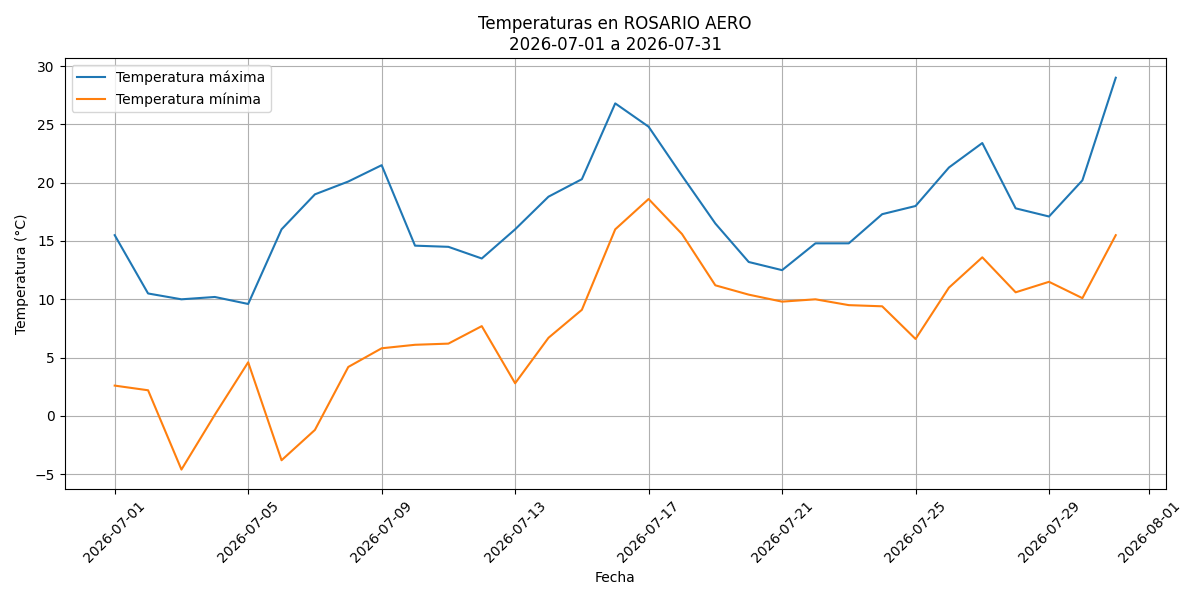

In [190]:
# PRUEBA DE LA HERRAMIENTA DE GRAFICAR TEMPERATURA CON EL AGENTE

consultar_agente("Mostrame un gráfico de la temperatura máxima y mínima de Rosario durante julio de 2026")

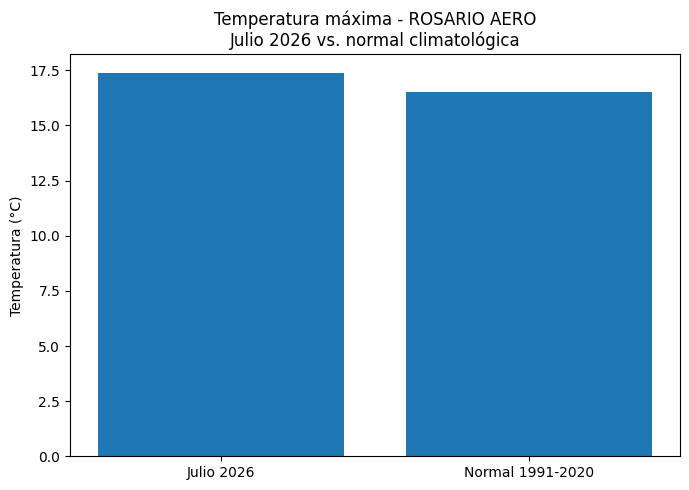

Aquí tienes la comparación de la temperatura máxima de **Rosario (ROSARIO AERO)** durante el mes de **julio de 2026** en relación con la normal climatológica 1991-2020, basada en los informes oficiales almacenados:

* **Temperatura máxima promedio observada (julio 2026):** **17.4 °C**
* **Normal climatológica (1991-2020):** **16.5 °C**
* **Anomalía / Diferencia:** **+0.9 °C**

**Conclusión:** 
Durante julio de 2026, la temperatura máxima media en Rosario se situó **por encima de los valores normales** climatológicos del período 1991-2020, registrando una diferencia positiva de casi un grado (+0.9 °C).

In [11]:
consultar_agente("Comparame la temperatura máxima de Rosario durante julio de 2026 con la normal climatológica 1991-2020")



> Entering new AgentExecutor chain...


c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



Invoking: `comparar_temperatura_con_normal` with `{'estacion': 'ROSARIO AERO', 'anio': 2026, 'mes': 'julio', 'tipo_temperatura': 'maxima'}`




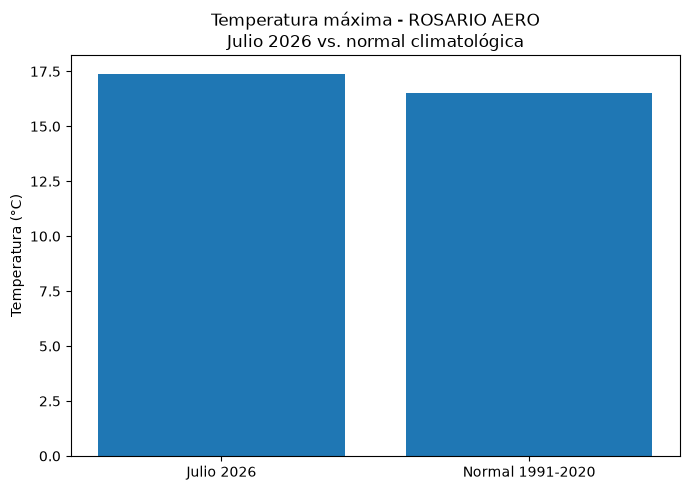

En ROSARIO AERO, la temperatura máxima promedio observada durante julio de 2026 fue de 17.4 °C. La normal climatológica 1991-2020 para ese mes es 16.5 °C. La diferencia fue de +0.9 °C, por lo que estuvo por encima de lo normal.

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Aquí tenés la comparación de la temperatura máxima de **Rosario (ROSARIO AERO)** durante **julio de 2026** frente a la normal climatológica 1991-2020, obtenida de los informes oficiales del SMN:\n\n* **Temperatura máxima promedio observada (julio 2026):** **17.4 °C**\n* **Normal climatológica (1991-2020):** **16.5 °C**\n* **Anomalía:** **+0.9 °C**\n\n**Conclusión:**\nDurante julio de 2026, la temperatura máxima media en Rosario se situó **por encima de lo normal** en casi un grado centígrado (+0.9 °C) respecto al periodo de referencia 1991-2020.', 'index': 0, 'extras': {'signature': 'El4KXAERTTIP7w+DmPG6Jf5E4jbTjV+i7IVZO/KhJvZBNna6ffTgqMhVudMqqFagDTbnqZcqhBLwnxgpU8rzX3giL0CyeoIGRrR186Fmb4wihj3GTVKly0Ur3/OkKG6T'}}]

> Finished chain.
[{'type': 'text', 'text': 'Aquí tenés la comparación de la temperatura máxima de **Rosario (ROSARIO AERO)** durante **julio de 2026** frente a la normal climatológica 1991-2020, obtenida de los informes oficiales del SMN:\n\n* **T

In [ ]:
# Muestra de la cadena

resultado = agent_executor.invoke({
    "input": "Comparame la temperatura máxima de Rosario durante julio de 2026 con la normal climatológica 1991-2020"
})

print(resultado["output"])

In [49]:
consultar_agente("Según los informes del SMN, ¿cómo fueron las precipitaciones durante mayo de 2026?. Además, cómo se compararon con otoño 2026?")

Según los informes del Servicio Meteorológico Nacional (SMN) para el año 2026, las características de las precipitaciones en **mayo de 2026** y su relación con el contexto general del **otoño de 2026** se detallan a continuación:

### **Precipitaciones en Mayo de 2026**
* **Escasez generalizada:** Gran parte del país (incluyendo el Noroeste Argentino - NOA, Cuyo y el centro/zona central de la Patagonia) registró acumulados inferiores a los 20 mm. En varias localidades, como La Quiaca o Ceres, **no se registraron precipitaciones** durante todo el mes.
* **Frecuencia de días con lluvia:** Predominaron las anomalías negativas en la cantidad de días con precipitaciones en gran parte del territorio nacional (con menores registros en zonas como Dolores, Concordia y Ezeiza).
* **Eventos extremos puntuales:** A pesar de la sequía predominante, se destacaron algunos eventos aislados de lluvias y tormentas fuertes en Chaco, el este de Buenos Aires y el norte de Entre Ríos. 
* **Excepciones húmedas:** Los mayores acumulados diarios y desvíos positivos se registraron de manera muy localizada, destacándose la zona cordillerana de Neuquén (con registros superiores a los 300-500 mm en puntos específicos como Cerro Mirador) y algunos sectores de la provincia de Buenos Aires (como Tres Arroyos y Mar del Plata).

---

### **Comparación con el Otoño de 2026 (Marzo, Abril y Mayo)**
* **Comportamiento estacional vs. mensual:** Mientras que mayo se caracterizó por una marcada escasez de lluvias y anomalías negativas generalizadas, el **otoño de 2026 en su conjunto** presentó acumulados muy significativos.
* **Volúmenes acumulados estacionales:** Durante toda la estación otoñal, las precipitaciones superaron los **400 mm** en amplias regiones del norte y centro del país (como gran parte de Formosa y Chaco, norte de Corrientes y Santa Fe, sudeste de Santiago del Estero y el centro de Buenos Aires), evidenciando que los meses previos (marzo y/o abril) compensaron con creces la sequía experimentada en el tramo final del otoño (mayo).

In [ ]:
# PRUEBA DE LA HERRAMIENTA DE BUSCAR INFORMACIÓN EN LOS PDF CON EL AGENTE
resultado = agent_executor.invoke({
    "input": "Según los informes del SMN, ¿cómo fueron las precipitaciones durante mayo de 2026?"
})

print(resultado["output"])



> Entering new AgentExecutor chain...


c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



Invoking: `buscar_informacion_texto` with `{'query': 'mayo 2026 precipitaciones'}`


--- [Fuente: files\Clim-Otoño 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Otoño  2026  - Vol. XXXVIII
6
SMN
FIG. 3 – Desvío de la precipitación con respecto a la normal 
1991-2020 (mm) de marzo, abril y mayo de 2026.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 9)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
6
SMN
FIG. 5 – Frecuencia de días con lluvia.
FIG. 6 – Frecuencia de días con lluvia de primera, 
segunda y tercera década.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 5)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
2
SMN
CARACTERÍSTICAS CLIMÁTICAS 
1 - PRECIPITACIÓN
1.1 - Precipitación media
Durante el mes de mayo, una extensa zona del país que comprende al Noroeste Argentino (NOA), 
Cuyo, centro y zona central de la Patagonia presentó precipitaciones inferiores a 20 mm (Figura 1- 
isolínea negra). En varias localidades no se registraron precipitaciones, por ejemplo: 

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



Invoking: `buscar_informacion_texto` with `{'query': 'mayo 2026 precipitacion desvio normal'}`


--- [Fuente: files\Clim-Otoño 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Otoño  2026  - Vol. XXXVIII
6
SMN
FIG. 3 – Desvío de la precipitación con respecto a la normal 
1991-2020 (mm) de marzo, abril y mayo de 2026.

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 6)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
3
SMN
FIG. 2 – Desvío de la precipitación con respecto a la normal 1991-2020 (mm)
• Entre Ríos: Concordia con 101.4 mm;
• Buenos Aires: Tres Arroyos con 129.1 mm, Mar del Plata con 105.1 mm y Villa Gesell con 71.3 mm;
• zona cordillerana de Neuquén: Cerro Mirador con 552.3 mm, Añihuerraqui con 396.3 mm, El Rincón 
con 393 mm, Puesto Antiao con 318.2 mm, Las Lagunas con 307.5 mm, Caviahue con 242.1 mm y 
Lago Espejo Chico con 222 mm;

--- [Fuente: files\Clim-Mayo 2026.pdf (Pág. 10)] ---
Boletín Climatológico -  Mayo  2026  - Vol. XXXVIII
7
SMN
FIG. 7 – Desvío de la frecu

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': 'Según los informes del Servicio Meteorológico Nacional (SMN) para **mayo de 2026**, las características principales de las precipitaciones fueron las siguientes:\n\n* **Precipitaciones escasas en gran parte del país:** Una extensa zona que abarcó el Noroeste Argentino (NOA), Cuyo, el centro y la zona central de la Patagonia registró acumulados **inferiores a 20 mm**. En varias localidades **no se registraron precipitaciones**, tales como La Quiaca y Ceres.\n* **Máximos acumulados mensuales:** Los registros más importantes del mes se concentraron en áreas puntuales, destacándose:\n  * **Zona cordillerana de Neuquén:** Cerro Mirador (552.3 mm), Añihuerraqui (396.3 mm), El Rincón (393 mm), Puesto Antiao (318.2 mm), Las Lagunas (307.5 mm), Caviahue (242.1 mm) y Lago Espejo Chico (222 mm).\n  * **Buenos Aires:** Tres Arroyos (129.1 mm), Mar del Plata (105.1 mm) y Villa Gesell (71.3 mm).\n  * **Entre Ríos:** Concordia (101.4 mm).\n* **Eventos diarios destacados:** 

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Aquí tenés el gráfico con la evolución de las temperaturas máximas y mínimas registradas en la estación **BARILOCHE AERO** durante el mes de julio de 2026.

IMAGEN_GENERADA:grafico_temperatura.png

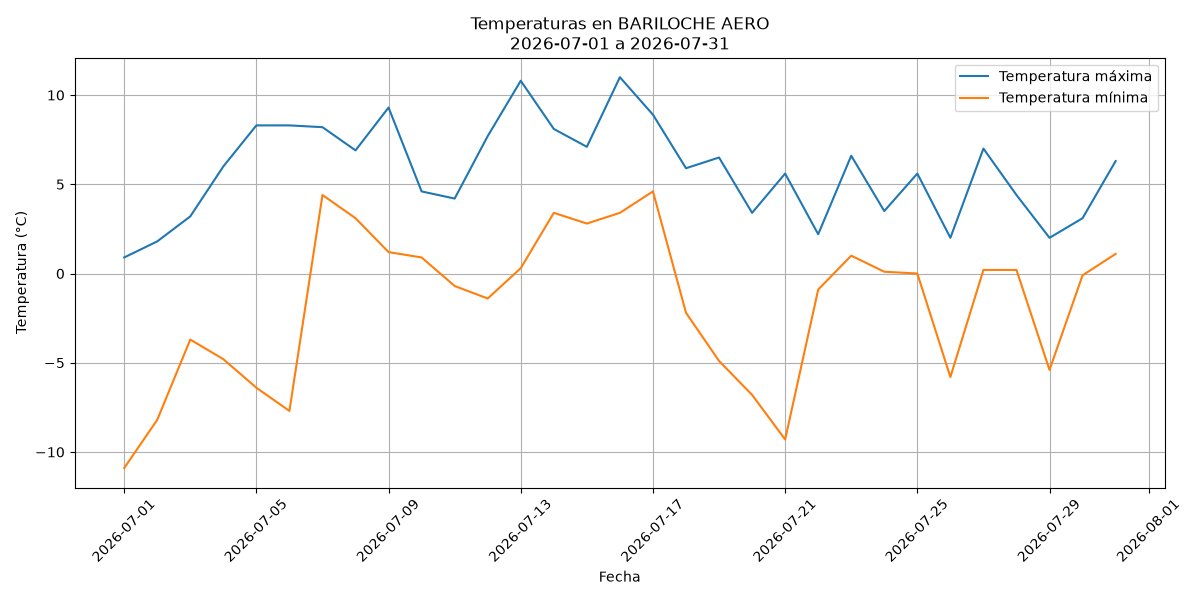

In [15]:
consultar_agente(
    "Graficame las temperaturas máximas y mínimas de Bariloche durante julio de 2026"
)

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


En **ROSARIO AERO**, la temperatura máxima registrada durante **julio de 2026** presentó el siguiente comportamiento en comparación con su período de referencia:

* **Temperatura máxima promedio observada:** 17.4 °C
* **Normal climatológica (1991-2020):** 16.5 °C
* **Anomalía / Diferencia:** **+0.9 °C**

Esto indica que el mes de julio de 2026 en Rosario experimentó temperaturas máximas **por encima de lo normal** en comparación con el promedio histórico de referencia.

IMAGEN_GENERADA:comparacion_temperatura_normal.png

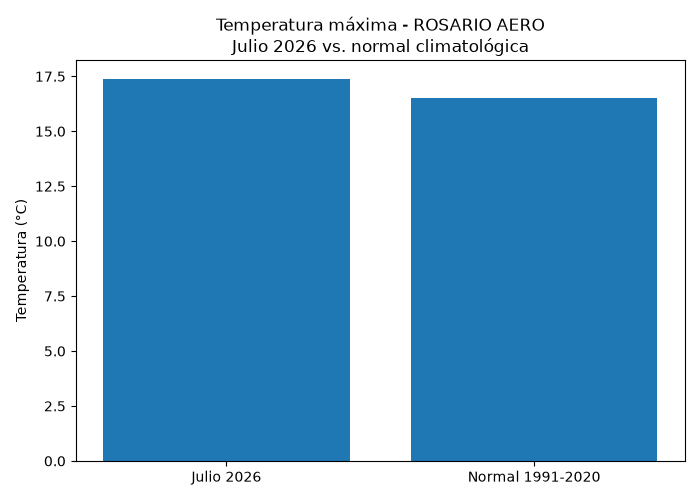

In [16]:
consultar_agente(
    "Comparame la temperatura máxima de Rosario en julio de 2026 con la normal climatológica"
)

In [22]:
consultar_agente(
    "¿Qué estaciones meteorológicas del SMN hay en la provincia de Santa Fe?"
)

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


En la provincia de **Santa Fe**, el Servicio Meteorológico Nacional (SMN) cuenta con las siguientes **7 estaciones meteorológicas**:

1. **CERES AERO**
   - **N° SMN:** 87257 | **OACI:** SANW
   - **Ubicación:** Latitud -29.87, Longitud -61.93 (Altura: 88 m s.n.m.)

2. **RAFAELA AERO**
   - **N° SMN:** 87360 | **OACI:** SAFR
   - **Ubicación:** Latitud -31.27, Longitud -61.50 (Altura: 99 m s.n.m.)

3. **RECONQUISTA AERO**
   - **N° SMN:** 87270 | **OACI:** SATR
   - **Ubicación:** Latitud -29.20, Longitud -59.68 (Altura: 53 m s.n.m.)

4. **ROSARIO AERO**
   - **N° SMN:** 87480 | **OACI:** SAAR
   - **Ubicación:** Latitud -32.90, Longitud -60.77 (Altura: 25 m s.n.m.)

5. **SAUCE VIEJO AERO** *(Área Metropolitana de Santa Fe)*
   - **N° SMN:** 87371 | **OACI:** SAAV
   - **Ubicación:** Latitud -31.70, Longitud -60.80 (Altura: 18 m s.n.m.)

6. **SUNCHALES AERO**
   - **N° SMN:** 87356 | **OACI:** SAFS
   - **Ubicación:** Latitud -30.95, Longitud -61.52 (Altura: 92 m s.n.m.)

7. **VENADO TUERTO AERO**
   - **N° SMN:** 87468 | **OACI:** SAFV
   - **Ubicación:** Latitud -33.67, Longitud -61.95 (Altura: 112 m s.n.m.)

In [23]:
consultar_agente(
    "Dame la ubicación, altura y códigos de la estación Rosario"
)

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


A continuación, te presento los datos de ubicación, altura y códigos de la estación meteorológica de Rosario:

* **Nombre de la estación:** ROSARIO AERO
* **Provincia:** Santa Fe
* **Ubicación:** 
  * Latitud: -32.9°
  * Longitud: -60.7667°
* **Altura:** 25 metros sobre el nivel del mar
* **Códigos:**
  * **N° SMN:** 87480
  * **OACI:** SAAR

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Durante el mes de julio de 2026, las temperaturas máximas promedio en ambas estaciones fueron las siguientes:

* **ROSARIO AERO:** **17.4 °C**
* **CORDOBA AERO:** **18.0 °C**

**CORDOBA AERO** registró una temperatura máxima promedio **0.7 °C mayor** que la de **ROSARIO AERO**.

IMAGEN_GENERADA:comparacion_estaciones.png

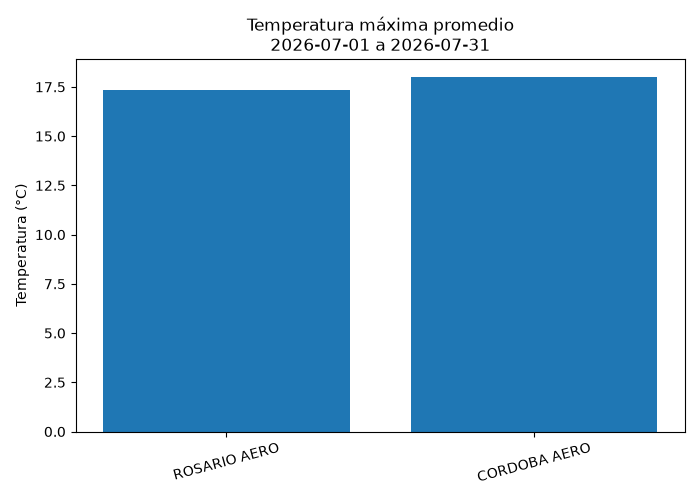

In [28]:
consultar_agente(
    "Comparame la temperatura máxima promedio de ROSARIO AERO y CORDOBA AERO durante julio de 2026"
)

In [36]:
consultar_agente(
    "¿Qué informa el SMN sobre El Niño durante 2026?"
)

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


De acuerdo con los informes del Servicio Meteorológico Nacional (SMN) actualizados a **septiembre de 2026**, esto es lo que se informa sobre el fenómeno **El Niño**:

* **Estado actual:** El sistema climático se encuentra transitando **condiciones El Niño** (fase cálida), con un valor en el Índice Oceánico de El Niño Relativo (RONI) de aproximadamente **+1 °C** durante el trimestre mayo-junio-julio de 2026.
* **Perspectivas para el trimestre SON (septiembre-octubre-noviembre 2026):**
  * **Probabilidad:** Los modelos dinámicos y estadísticos indican una **probabilidad del 100%** de que la fase de El Niño se mantenga activa.
  * **Anomalías térmicas:** En la región Niño 3.4 se prevén temperaturas de la superficie del mar (TSM) superiores a los valores normales, con un valor promedio en los modelos cercano a **+3 °C**.
  * **Intensidad:** Con respecto a la intensidad que podría alcanzar el evento, el informe destaca que existen **mayores chances de que sea un evento muy fuerte**.

In [40]:
consultar_agente(
    "Graficame la temperatura de ROSARIO AERO durante enero de 1990"
)

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


No se encontraron registros de temperatura para la estación **ROSARIO AERO** durante el período solicitado (enero de 1990) en la base de datos disponible. 

Si lo deseas, puedo intentar graficar los datos de un período posterior en el que la estación tenga registros disponibles.

In [41]:
consultar_agente(
    "¿Qué pronóstico de temperatura y precipitación presenta el SMN para septiembre, octubre y noviembre de 2026 en Argentina?"
)

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Según el **Pronóstico Climático Trimestral** elaborado por el Servicio Meteorológico Nacional (SMN) el **28 de agosto de 2026**, correspondiente al trimestre **septiembre - octubre - noviembre de 2026**, se destacan las siguientes previsiones generales:

* **Categorías analizadas:** El pronóstico probabilístico por consenso evalúa las chances de que las variables meteorológicas se presenten en las categorías **Superior a la normal**, **Normal** o **Inferior a la normal** (o combinaciones entre ellas, como Normal a Superior / Normal a Inferior), dependiendo de la región del país.
* **Escala y consideraciones:** Las previsiones se refieren a **condiciones medias** durante todo el trimestre y no contemplan eventos singulares de escala subestacional (tales como olas de calor/frío intensas, sistemas frontales específicos o bloqueos atmosféricos).
* **Áreas sin categoría predominante:** En ciertas regiones donde los modelos globales y estadísticos presentan diferencias o no muestran una señal clara, el área se indica sin una categoría con mayor probabilidad (o bajo climatología/estación seca), por lo que se recomienda considerar la información estadística histórica del trimestre.

*Nota: Se recomienda mantenerse actualizado con los pronósticos en escala diaria y semanal a través de los canales oficiales del SMN.*

In [43]:
consultar_agente(
    "Según el pronóstico trimestral del SMN, ¿qué regiones de Argentina tienen mayor probabilidad de registrar temperaturas superiores a lo normal entre septiembre y noviembre de 2026?"
)

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash

De acuerdo con el **Pronóstico Climático Trimestral (septiembre-octubre-noviembre 2026)** elaborado por el Servicio Meteorológico Nacional (SMN):

* **Contexto general y fase climática:** Las proyecciones de los modelos dinámicos y estadísticos indican que durante este trimestre se mantiene firmemente una **fase de El Niño**, con temperaturas de la superficie del mar (TSM) superiores a lo normal en la región ecuatorial del Pacífico (Niño 3.4).
* **Tendencia de temperatura:** Si bien el informe detalla las probabilidades para las distintas categorías térmicas mediante un sistema de consenso de modelos, los análisis asociados a este tipo de escenarios cálidos bajo la influencia de El Niño suelen favorecer desvíos térmicos positivos sobre gran parte del centro y norte del país. 

*(Nota: Para una descripción detallada región por región o porcentajes específicos de probabilidad, se sugiere consultar directamente los mapas oficiales de perspectivas de temperatura del trimestre en el portal del SMN).*

In [42]:
consultar_agente(
    "¿Cuáles fueron las principales características de la ola de frío analizada por el SMN durante 2026 y qué regiones fueron afectadas?"
)

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Según el **Informe Especial N°2 por Ola de Frío / Bajas Temperaturas (Temporada 2026)** del Servicio Meteorológico Nacional, el evento se desarrolló entre el **18 y el 31 de julio de 2026**. 

A continuación, se detallan sus principales características y las regiones afectadas:

* **Ingreso y bloqueo de la masa de aire polar:** El evento comenzó el 17 de julio con el ingreso de una masa de aire frío polar por el extremo sur de la Patagonia. Sin embargo, debido a una fuerte **circulación zonal entre los 30°S y 40°S**, el avance hacia latitudes más bajas quedó bloqueado (a diferencia de lo que ocurre habitualmente en este tipo de eventos), impidiendo que el frío extremo progresara hacia el norte del país.
* **Regiones más afectadas:** 
  * **Santa Cruz y Chubut:** Fueron las principales áreas alcanzadas por las condiciones de frío extremo. **Santa Cruz** resultó la provincia más afectada tanto en intensidad como en duración, quedando las marcas térmicas restringidas en su territorio.
  * **Región cordillerana central y norte:** Se registraron **nevadas extraordinarias**, con acumulaciones superiores a los **3 metros de altura** en provincias como **Catamarca, San Juan y Mendoza**.
* **Fenómenos asociados:** La persistencia de temperaturas extremadamente bajas en el sur estuvo acompañada por la **ocurrencia de frecuentes nevadas** y el **congelamiento de los suelos**. Un refuerzo adicional de aire frío ingresó a partir del 29 de julio, prolongando el evento hasta fin de mes.

Aquí tenés los mapas solicitados con la ubicación de las estaciones meteorológicas del Servicio Meteorológico Nacional (SMN):

### 1. Estaciones en la Provincia de Buenos Aires
IMAGEN_GENERADA:./generated_images/mapa_BUENOS_AIRES.png

---

### 2. Estaciones a Nivel Nacional (Todo el país)
IMAGEN_GENERADA:./generated_images/mapa_NACION.png

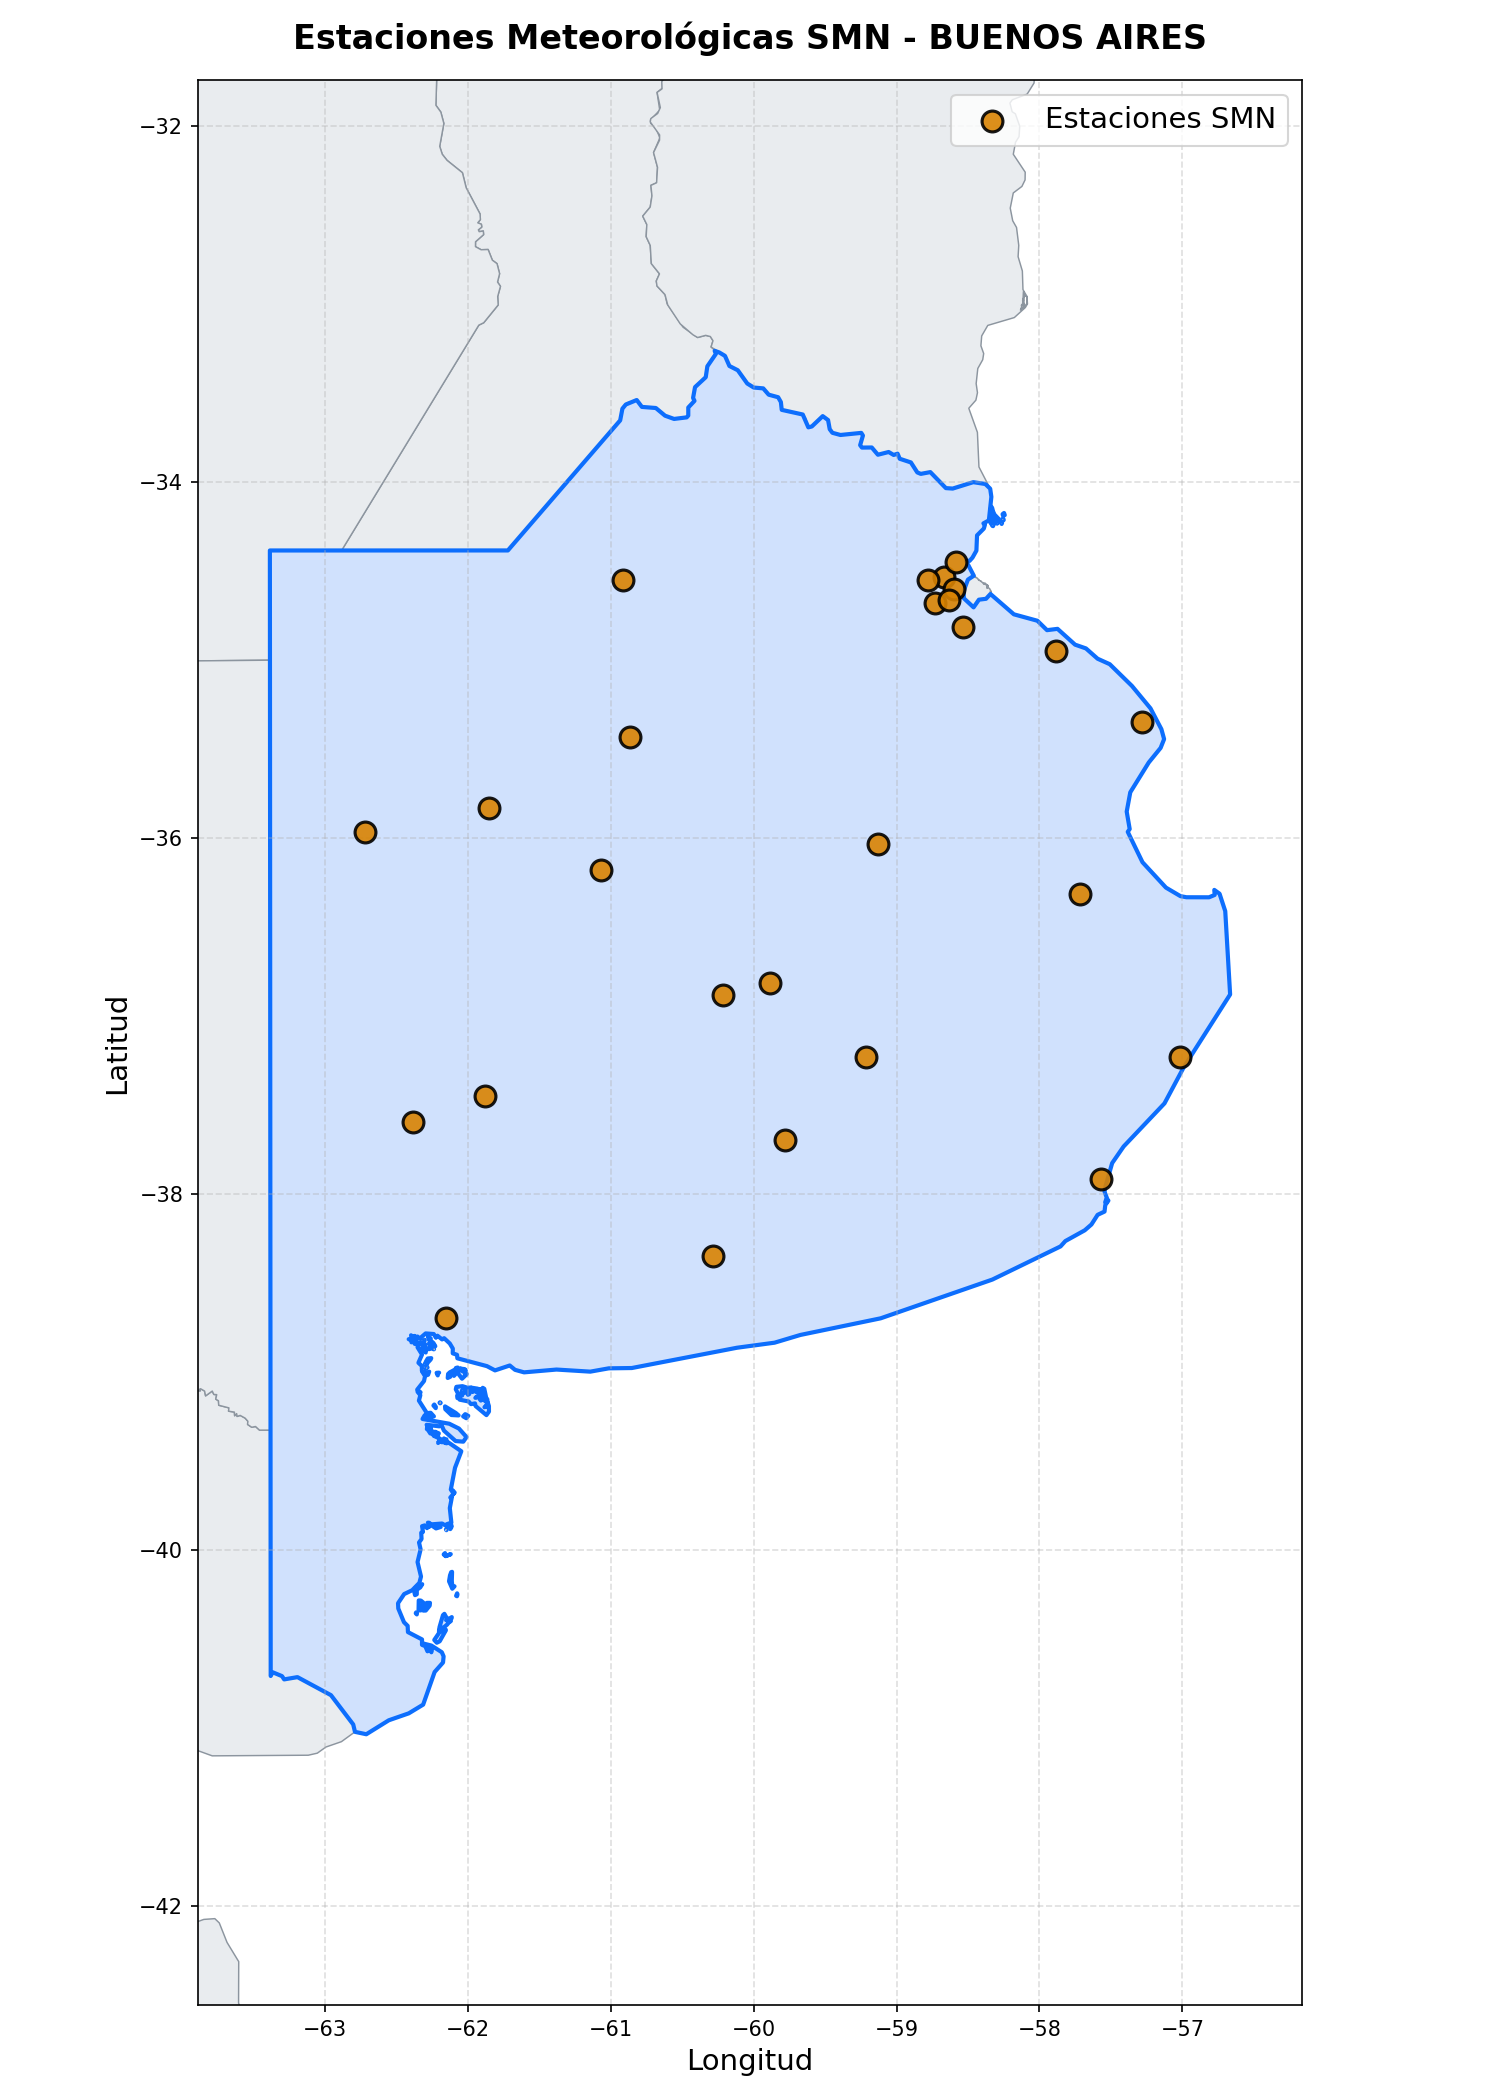

In [ ]:
consultar_agente(
  "Quisiera ver un mapa de las estaciones meteorologicas en buenos aires. Aparte, quiero ver las de todo el pais"
)

# TODO Ver como podemos modificar la funcion de consultar para que agarre multiples imagenes, no solo una. Actualmente parece que solo muestra la primera que genera.
# Y otro detalle es que esta imagen es enorme

c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
c:\Users\matia\Downloads\IA TP2\TP2-IA-RAG-SMN\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3719: UserWarning: Model 'gemini-3.5-flash

Aquí tenés los mapas con las estaciones meteorológicas del Servicio Meteorológico Nacional (SMN) para cada una de las regiones solicitadas y a nivel nacional:

### 1. Provincia de Buenos Aires
IMAGEN_GENERADA:./generated_images/mapa_BUENOS_AIRES.png

### 2. Antártida
IMAGEN_GENERADA:./generated_images/mapa_ANTARTIDA.png

### 3. Tierra del Fuego
IMAGEN_GENERADA:./generated_images/mapa_TIERRA_DEL_FUEGO.png

### 4. Todo el país (Nacional)
IMAGEN_GENERADA:./generated_images/mapa_NACION.png

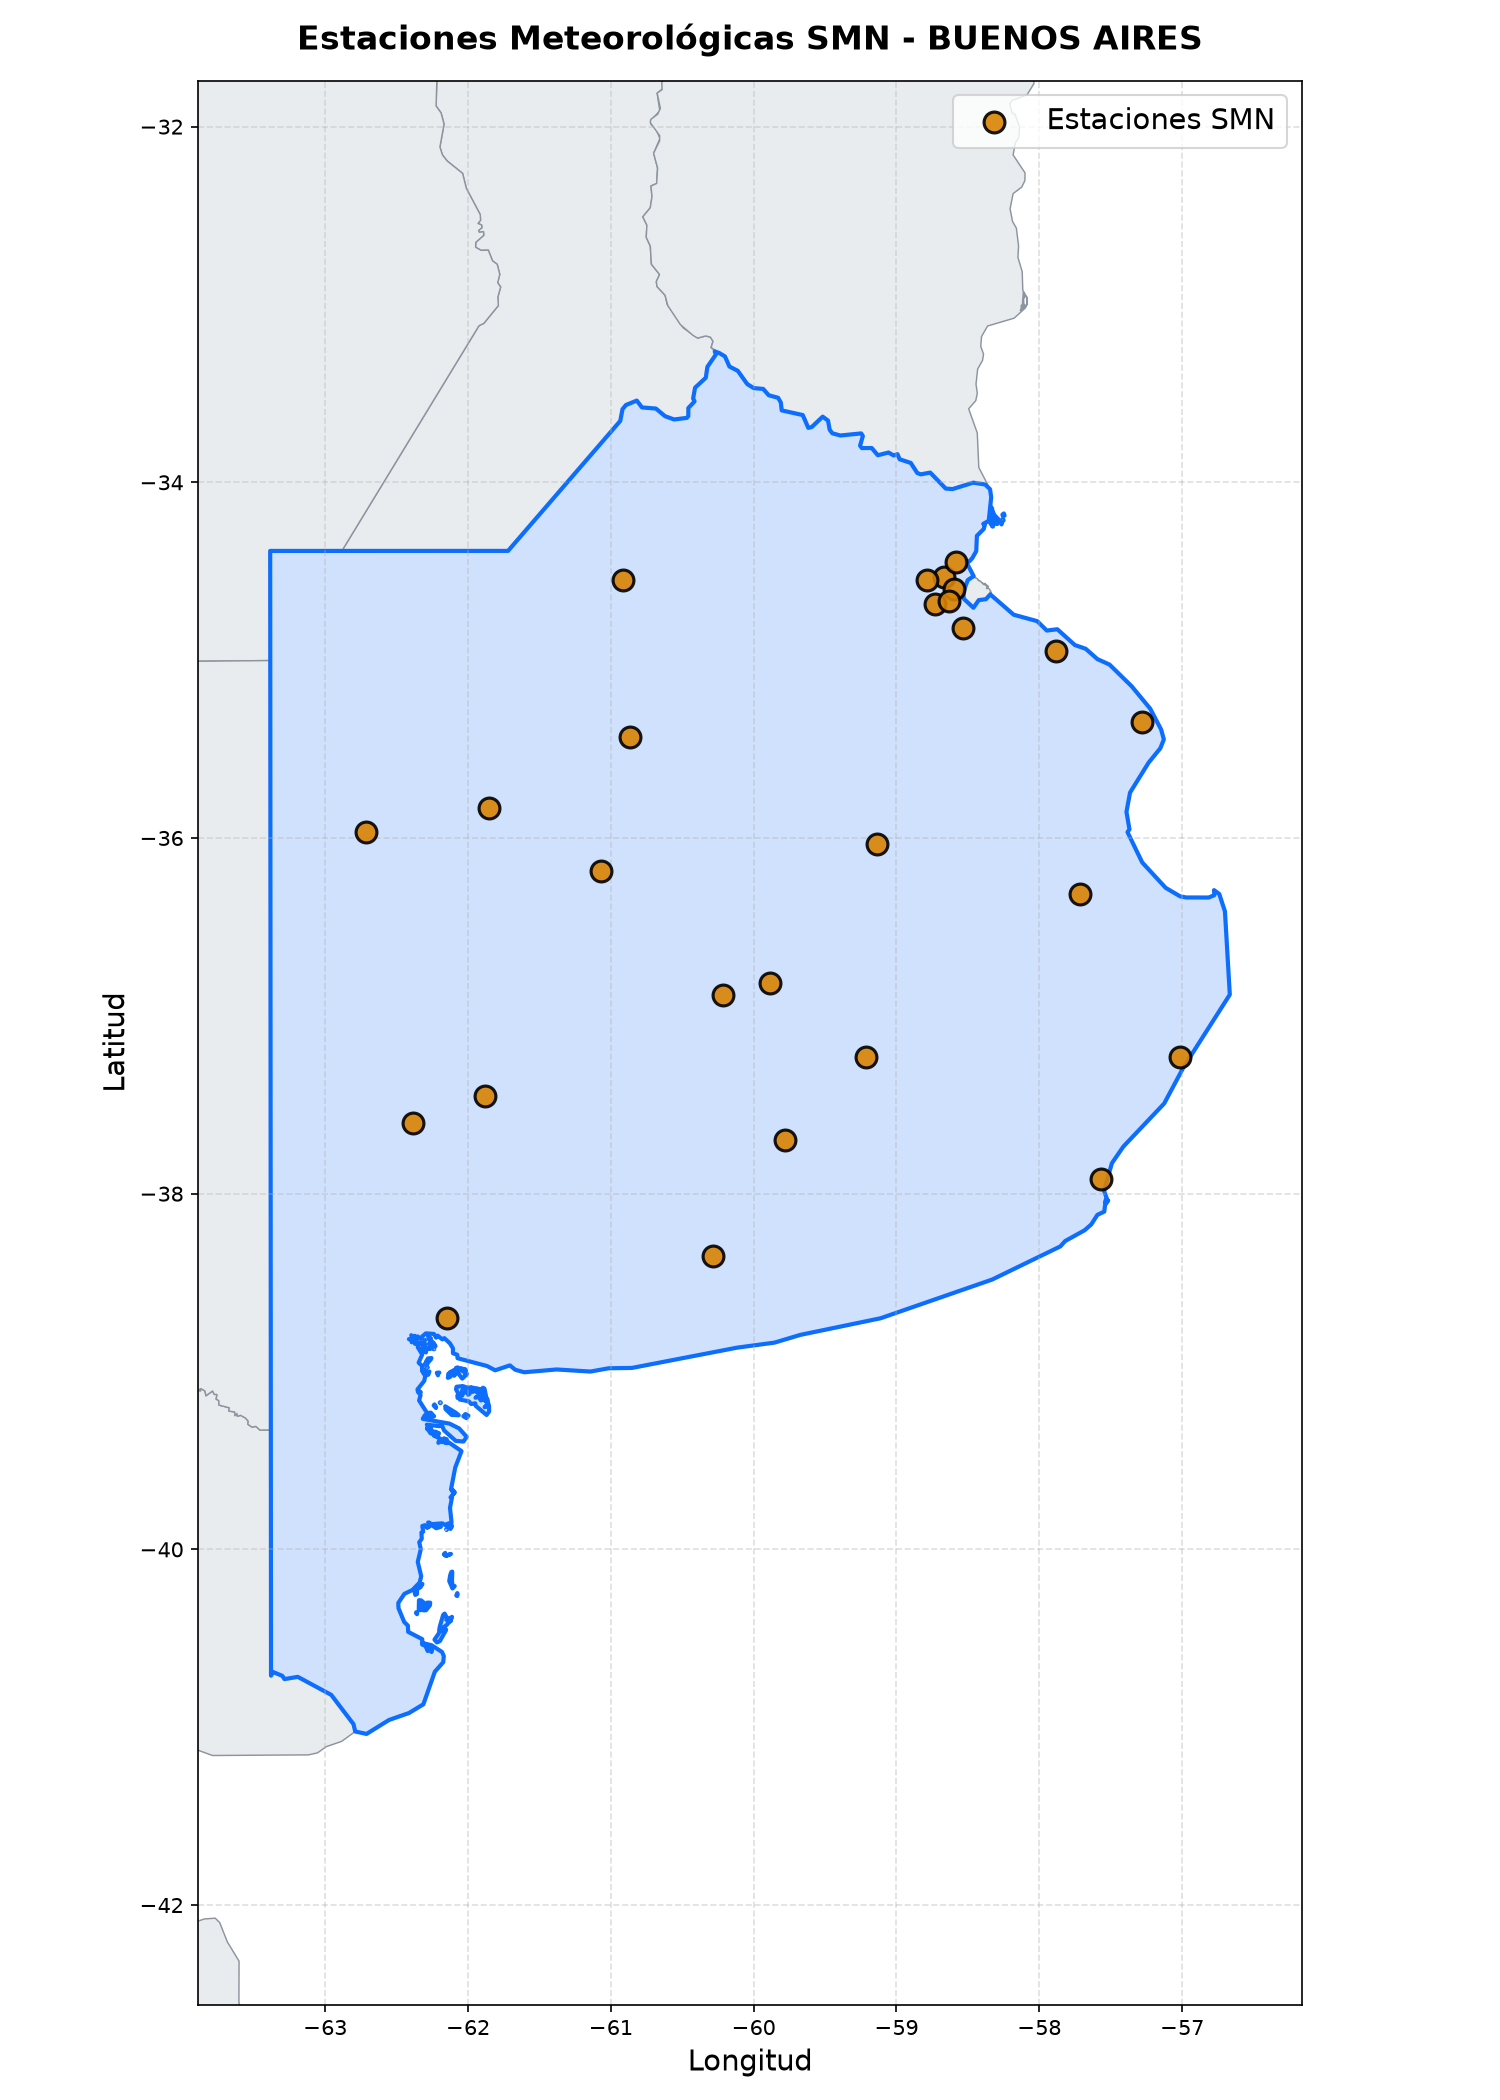

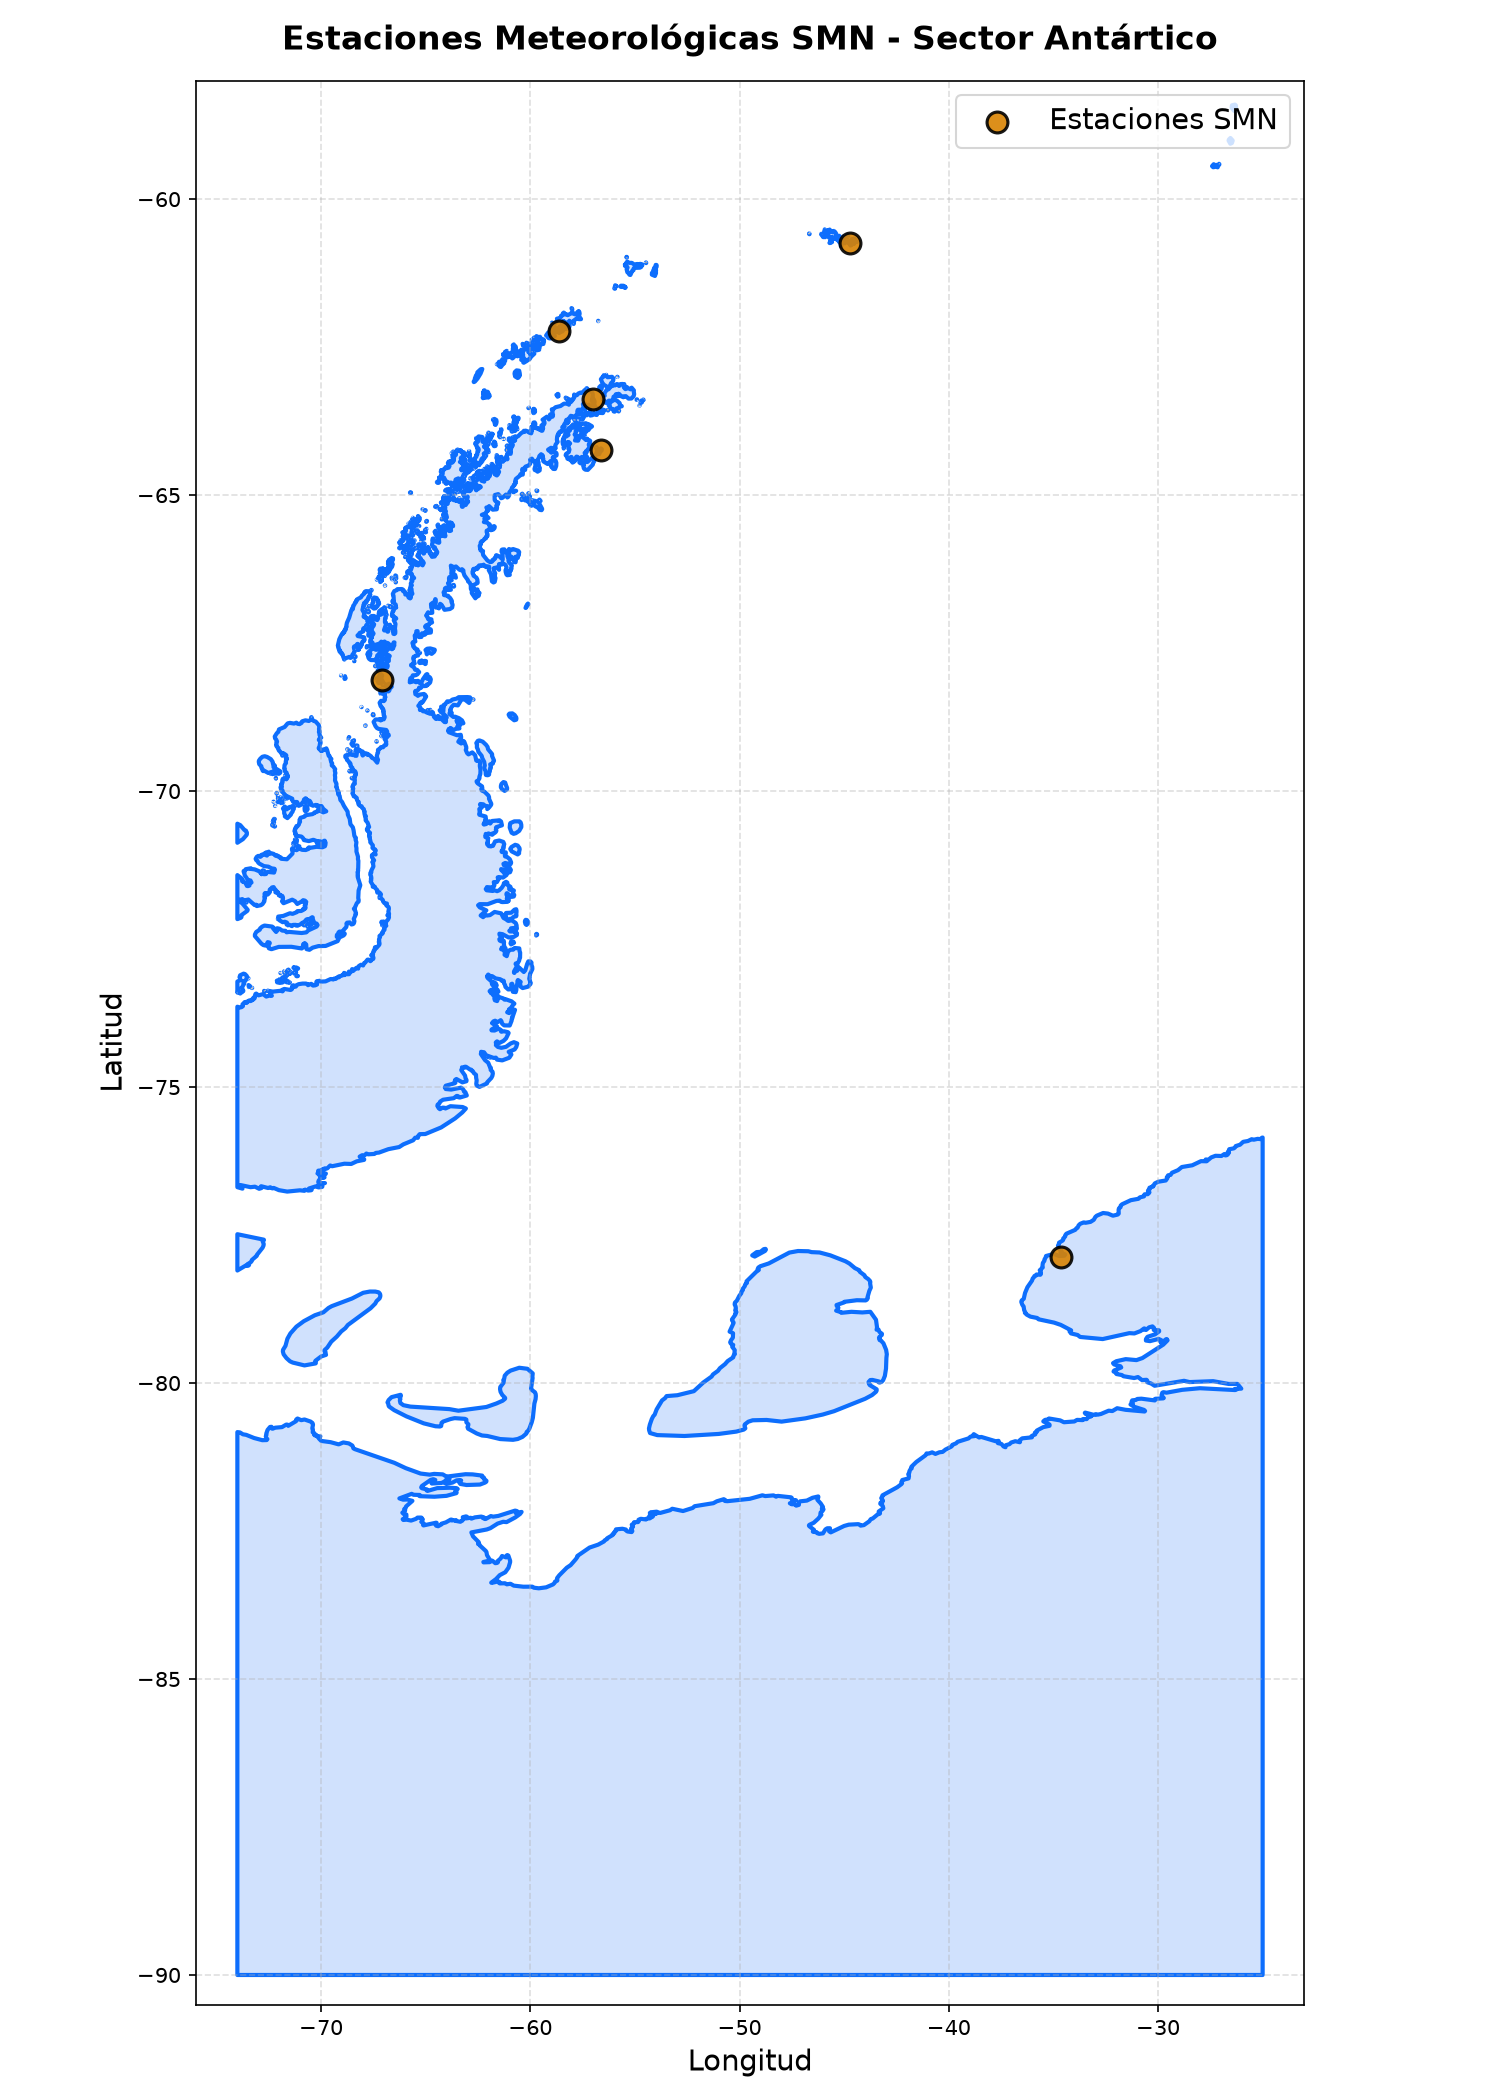

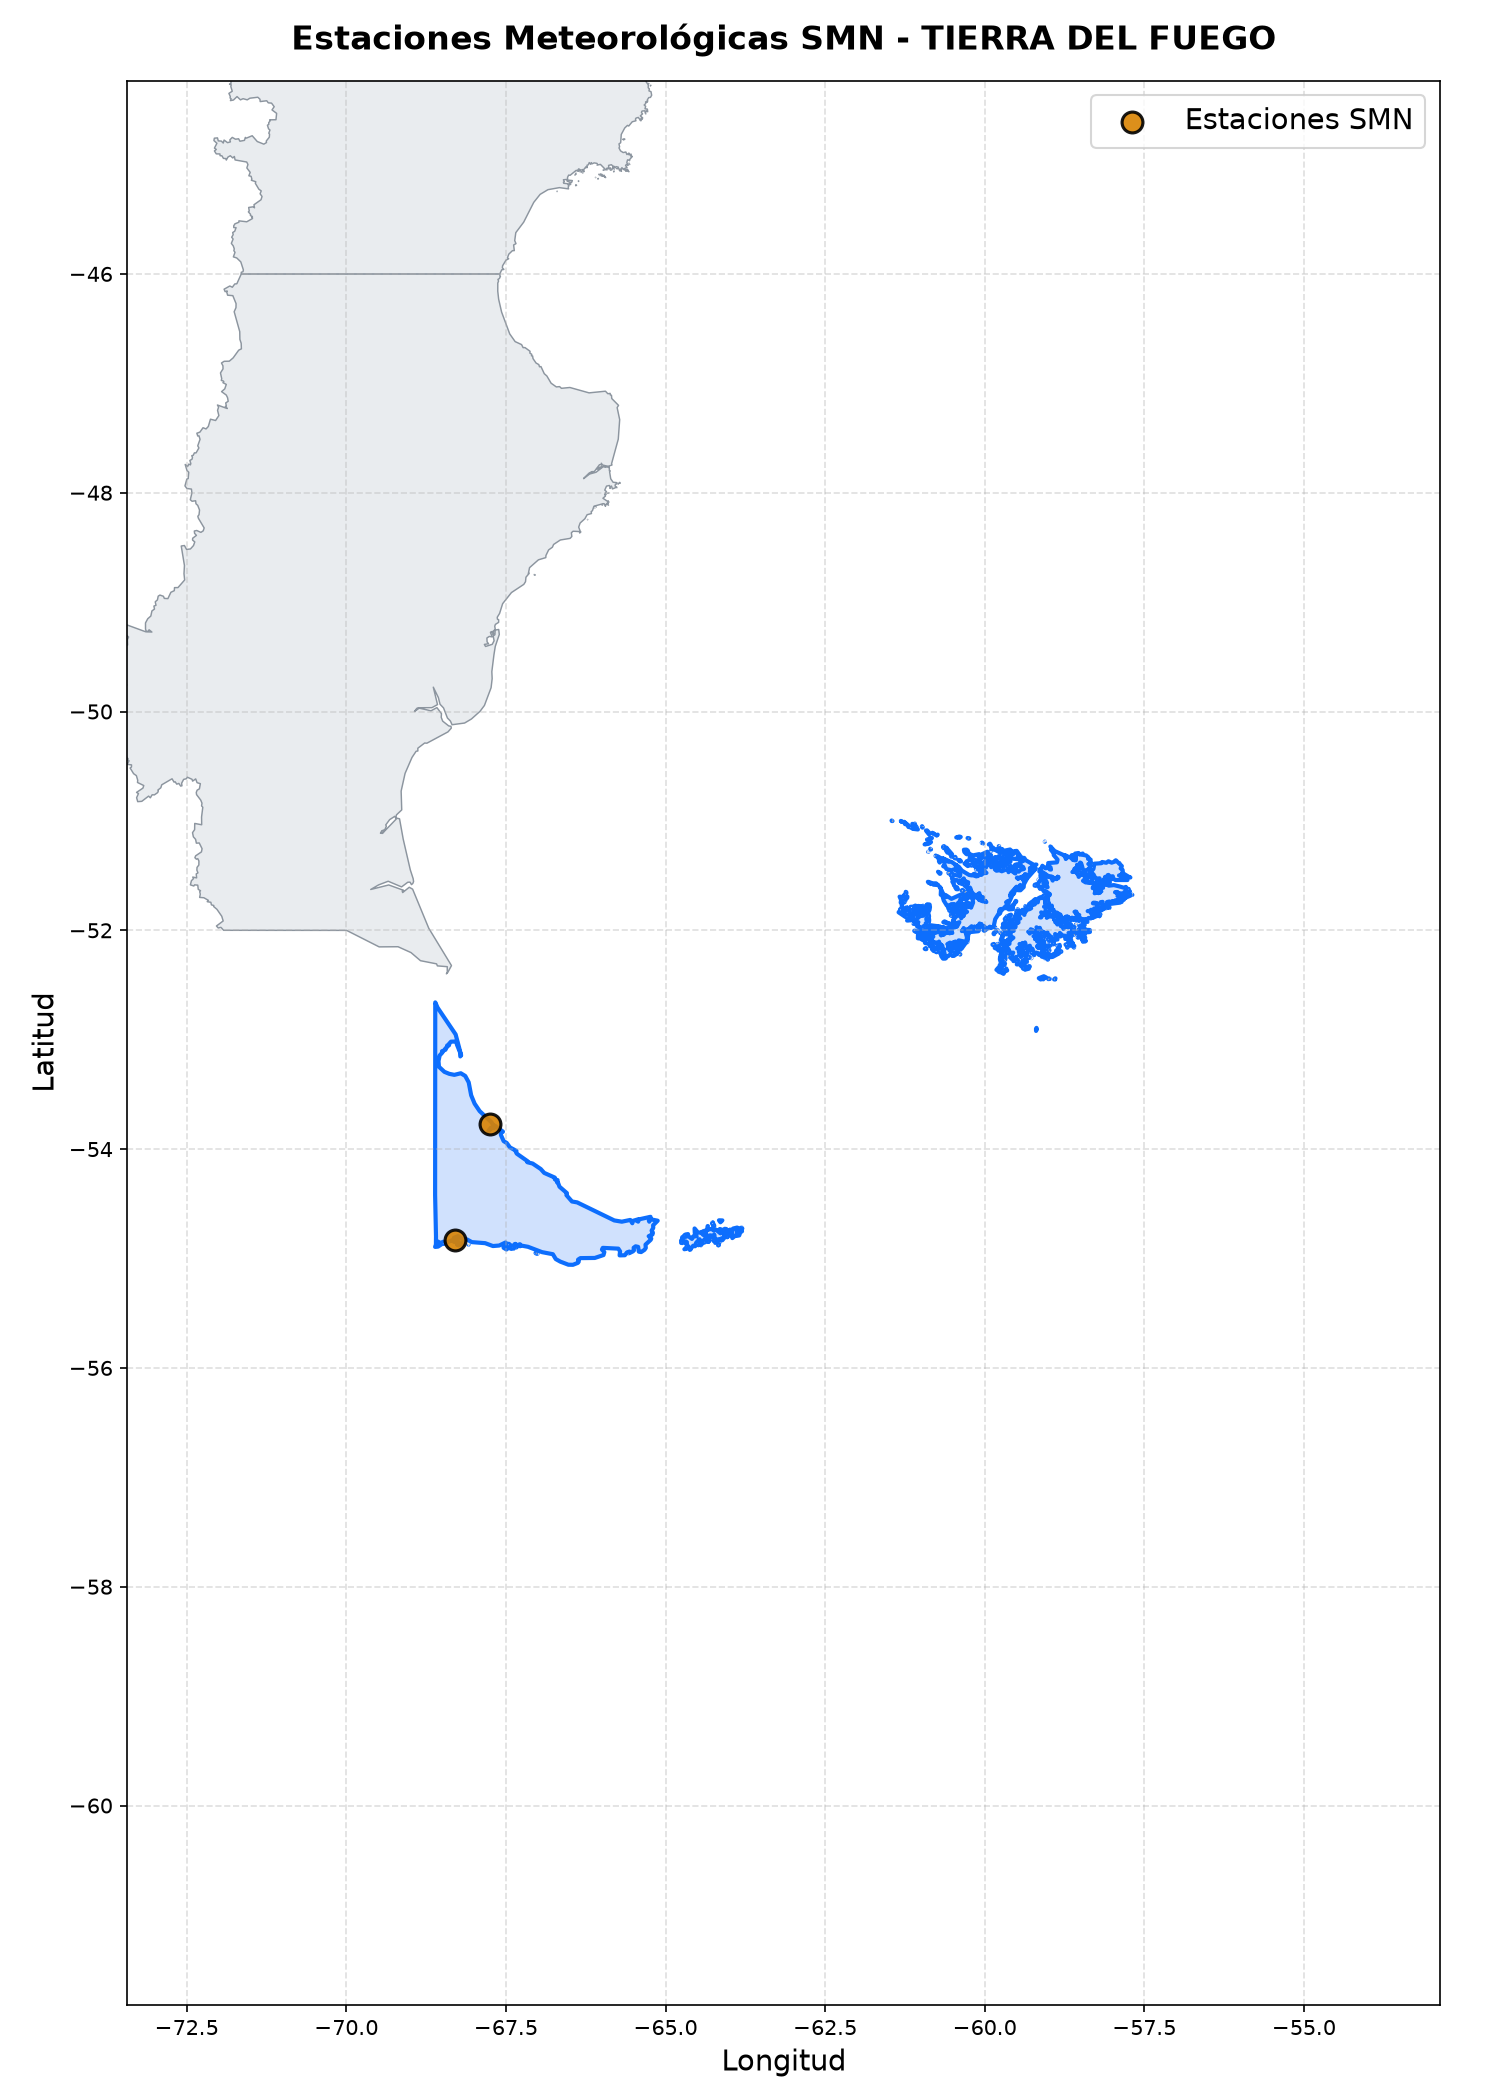

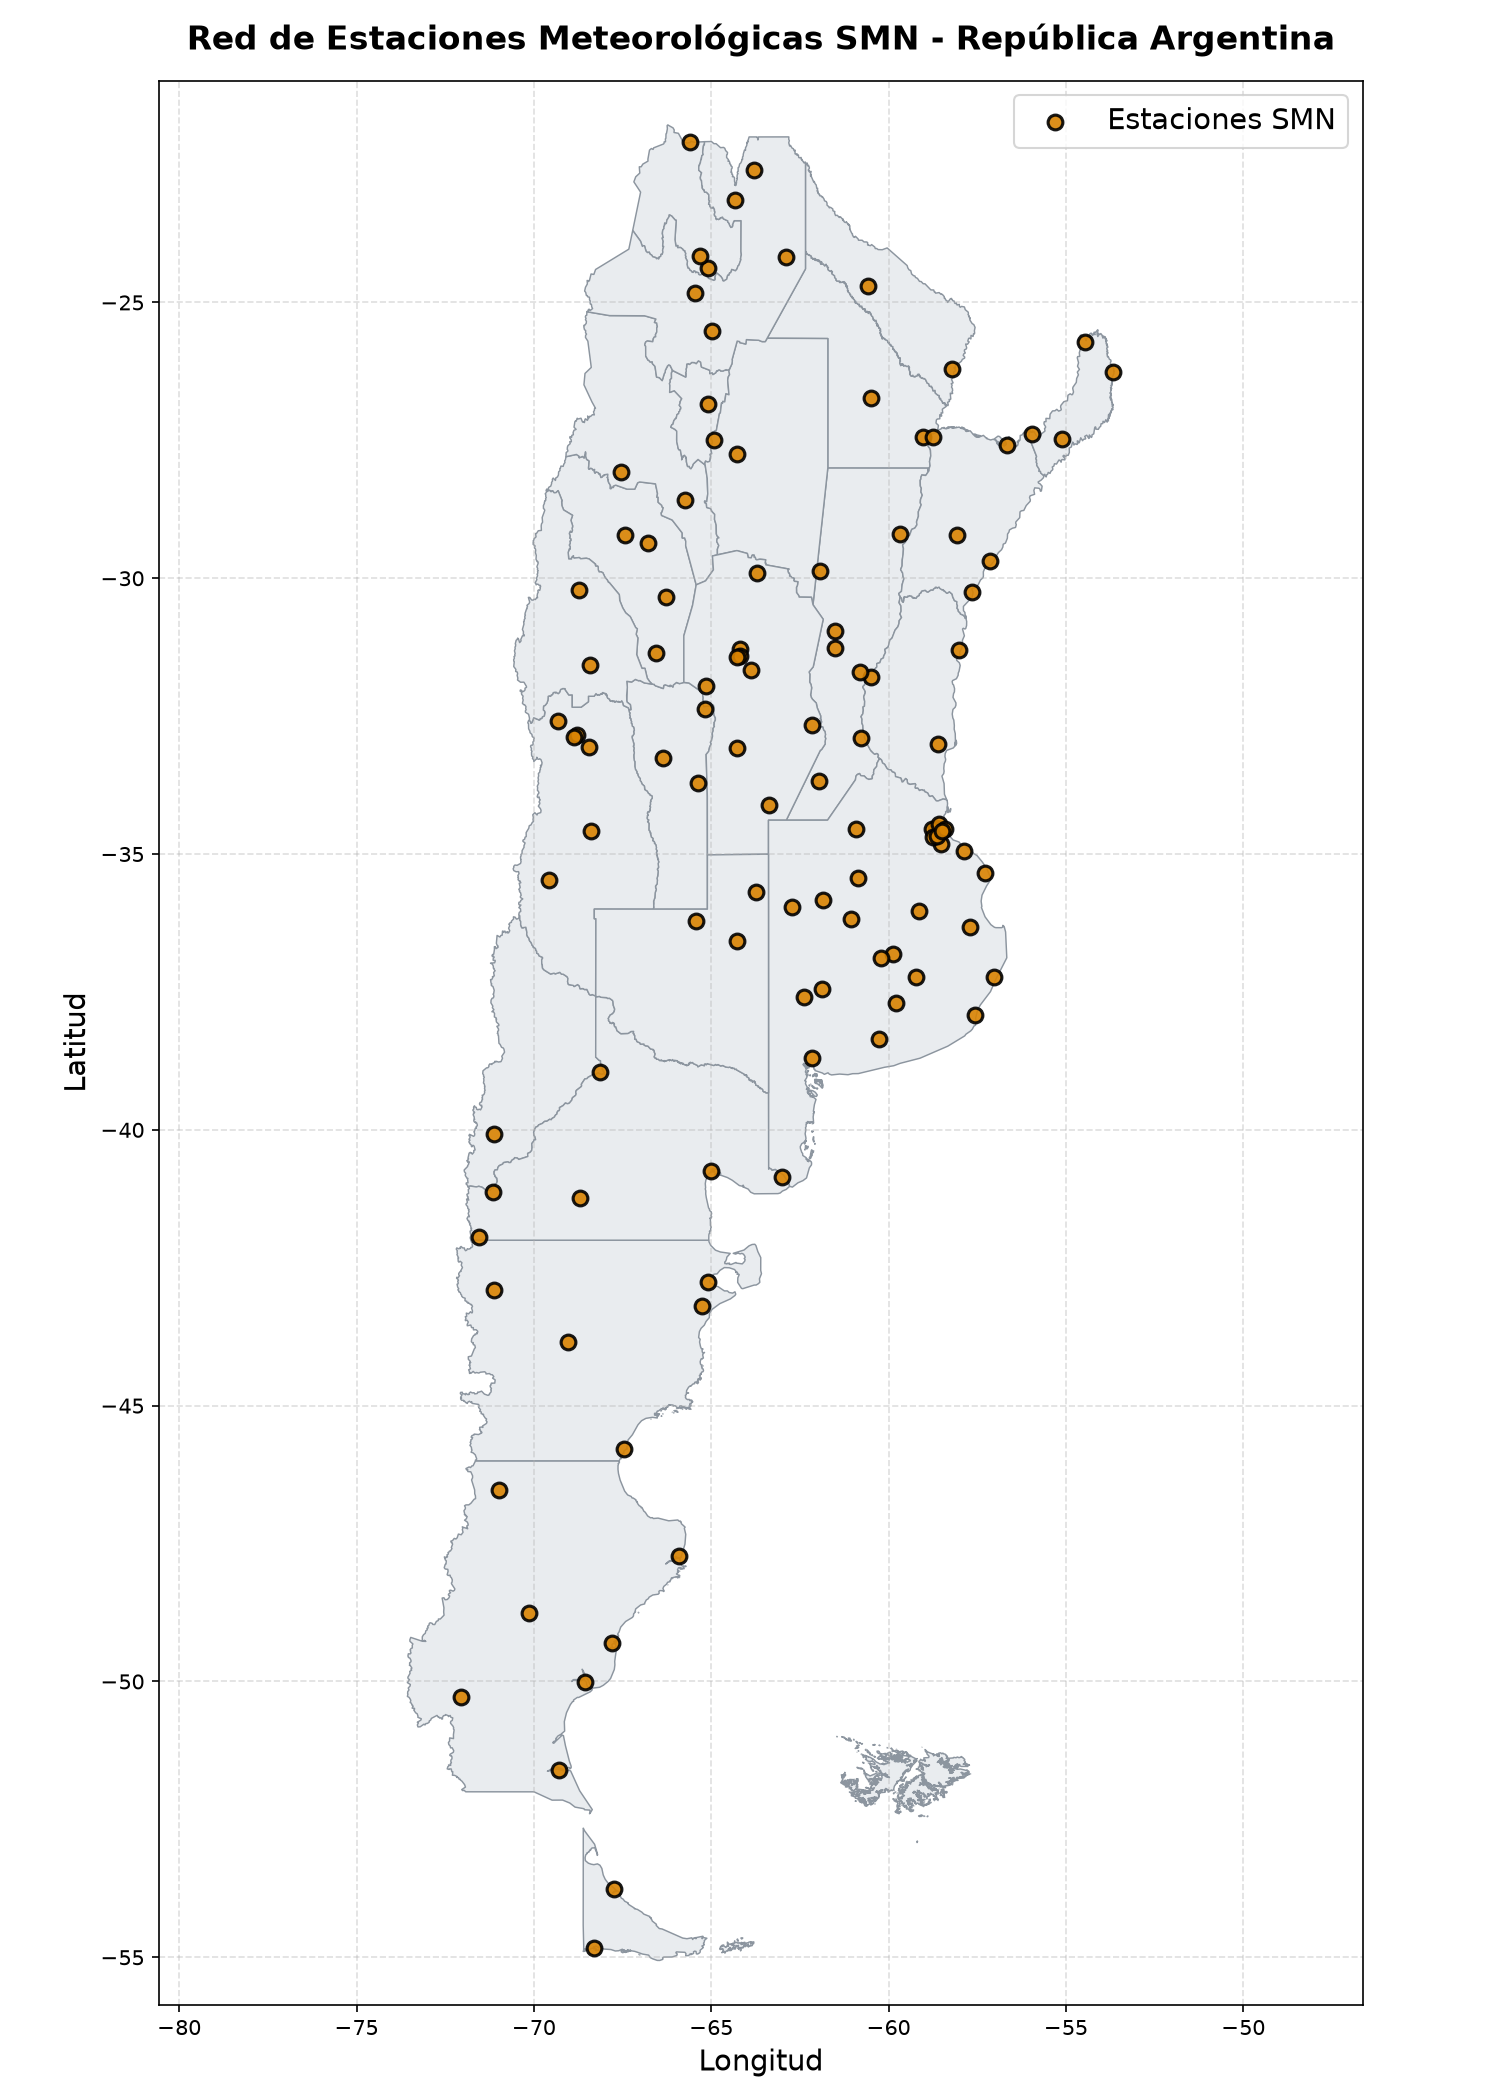

In [17]:
consultar_agente(
  "Quisiera ver un mapa de las estaciones meteorologicas en buenos aires, antartida, tierra del fuego, y todo el pais"
)